In [3]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

METHOD = "hmm_pomegranate"


In [4]:
import pandas as pd
import numpy as np

# 1. Read data

In [5]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/'  # windows
DATA_PATH_IMMUNOGENIC = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/'  # windows

# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

TARGET_PATH_TO_RESULTS = "experiment_results/low_iterations_training/"
# TARGET_PATH_TO_RESULTS = "experiment_results/backup/"


In [6]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")



per_allele_per_kfold_per_length_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "immunogenic")
per_allele_per_kfold_per_length_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "immunogenic")
per_allele_per_kfold_per_length_non_immunogenic_train = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "train", "nonimmunogenic")
per_allele_per_kfold_per_length_non_immunogenic_test = read_data(DATA_PATH_IMMUNOGENIC, ALLELES, "test", "nonimmunogenic")

ALLELES

['HLA-A*02:01']

# 2. Read models

In [7]:
from hmm_logic_methods import load_model, get_model_representation, get_all_paths_with_probs

In [8]:
RUNS = 2
target_length = 9
states = 18
allele_name = ALLELES[0]
target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
total_splits = len(per_allele_per_kfold_per_length_binders_train[allele_name])
split_num_immune = 1
run_num_immune = 0

per_name_binding_models = dict()
per_name_immune_models = dict()
per_name_models_root = dict()

name_to_run = dict()
name_to_split = dict()
# Source path 1
MODELS_PATH = "experiment_results/low_iterations_training/"
#Binding models

selected_binding_models = list()
for run_num_b in range(RUNS):
    for split_num_b in range(total_splits):
        binding_model_name = f"{run_num_b}_run-9-18-st-baum-welch-alg-30-min_iters_model-{target_allele_name}-{split_num_b}"
        selected_binding_models.append(binding_model_name)
        name_to_run[binding_model_name] = run_num_b
        name_to_split[binding_model_name] = split_num_b


#Aux binding models
aux_models = list()
selected_binding_1 = f"{1}_run-{target_length}-{states}-st-baum-welch-alg-30-min_iters-69-max_iters_model-{target_allele_name}-{2}"
name_to_run[selected_binding_1] = 1
name_to_split[selected_binding_1] = 2
selected_binding_2 = f"{1}_run-{target_length}-{states}-st-baum-welch-alg-30-min_iters-69-max_iters_model-{target_allele_name}-{0}"
name_to_run[selected_binding_2] = 1
name_to_split[selected_binding_2] = 0
selected_binding_3 = f"{0}_run-{target_length}-{states}-st-baum-welch-alg-30-min_iters-69-max_iters_model-{target_allele_name}-{3}"
name_to_run[selected_binding_3] = 0
name_to_split[selected_binding_3] = 3
aux_models.append(selected_binding_1)
aux_models.append(selected_binding_2)
aux_models.append(selected_binding_3)
selected_binding_models.append(selected_binding_1)
selected_binding_models.append(selected_binding_2)
selected_binding_models.append(selected_binding_3)

selected_binding_models = selected_binding_models[4:5]

for model_name in selected_binding_models:
    per_name_binding_models[model_name] =  load_model(MODELS_PATH, model_name)
    per_name_models_root[model_name] = MODELS_PATH



selected_immune_models = list()

for model_name in selected_binding_models:
    selected_immune_model = f"{run_num_immune}_run_imm-{target_length}-mer-of-[{model_name}]_model-{target_allele_name}-{split_num_immune}"
    selected_immune_models.append(selected_immune_model)
# selected_immune_models = selected_immune_models[4:5]
for model_name in selected_immune_models:
    per_name_immune_models[model_name] =  load_model(MODELS_PATH, model_name)
    per_name_models_root[model_name] = MODELS_PATH


In [15]:
selected_immune_models

['0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4]_model-HLA_A_02_01-1']

In [10]:
model = per_name_immune_models[model_name]

In [11]:
model.keymap

[{'H': 0,
  'R': 1,
  'V': 2,
  'S': 3,
  'N': 4,
  'Q': 5,
  'W': 6,
  'K': 7,
  'M': 8,
  'D': 9,
  'I': 10,
  'Y': 11,
  'C': 12,
  'L': 13,
  'G': 14,
  'F': 15,
  'A': 16,
  'P': 17,
  'T': 18,
  'E': 19}]

# Generate peptides 5000 for each model

In [16]:
%%time
count_to_generate = 5000
per_name_generated_peptides = dict()

for model_name, model in per_name_binding_models.items():
    per_name_generated_peptides[model_name] = ["".join(model.sample()) for i in range(count_to_generate)]
for model_name, model in per_name_immune_models.items():
    per_name_generated_peptides[model_name] = ["".join(model.sample()) for i in range(count_to_generate)]

Wall time: 4.96 s


# Find possible paths for each model

In [17]:
TOP = 40

In [18]:
%%time
per_name_paths = dict()
per_name_edge_to_prob_b = dict()
print("Binding_models")
for model_name, model in per_name_binding_models.items():
    per_name_paths[model_name], per_name_edge_to_prob_b[model_name] = get_all_paths_with_probs(model)
print("Immune models")
for model_name, model in per_name_immune_models.items():
    per_name_paths[model_name], per_name_edge_to_prob_b[model_name] = get_all_paths_with_probs(model)


Binding_models
Converting graph for model (0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4) (Delete zero edges)
found 144 paths
Immune models
Converting graph for model (0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4]_model-HLA_A_02_01-1) (Delete zero edges)
found 120 paths
Wall time: 1.16 s


## Make representation dfs for Train, Test, Generated for each model

In [19]:
%%time
per_name_representation_train = dict()
per_name_representation_test = dict()
per_name_representation_generated = dict()
for allele_name in ALLELES:
    for (binding_model_name, binding_model), (immune_model_name, immune_model) in zip(per_name_binding_models.items(),per_name_immune_models.items()):
        train_peptides_b = per_allele_per_kfold_per_length_binders_train[allele_name][name_to_split[binding_model_name]][target_length]
        train_peptides_i = per_allele_per_kfold_per_length_immunogenic_train[allele_name][split_num_immune][target_length]
        test_peptides_b = per_allele_per_kfold_per_length_binders_test[allele_name][name_to_split[binding_model_name]][target_length]
        test_peptides_i = per_allele_per_kfold_per_length_immunogenic_test[allele_name][split_num_immune][target_length]

        generated_peptides_b = per_name_generated_peptides[binding_model_name]
        generated_peptides_i = per_name_generated_peptides[immune_model_name]
        print("Train")
        train_peptides_repr_data_b_model_b, _ = get_model_representation(binding_model, set(train_peptides_b), edge_value="log_probability", top_paths=TOP)
        train_peptides_repr_data_b_model_i, _ = get_model_representation(immune_model, set(train_peptides_b), edge_value="log_probability",  top_paths=TOP)
        train_peptides_repr_data_i_model_b, _ = get_model_representation(binding_model, set(train_peptides_i), edge_value="log_probability",  top_paths=TOP)
        train_peptides_repr_data_i_model_i, _ = get_model_representation(immune_model, set(train_peptides_i), edge_value="log_probability",  top_paths=TOP)

        print("Test")
        test_peptides_repr_data_b_model_b, _ = get_model_representation(binding_model, set(test_peptides_b), edge_value="log_probability",  top_paths=TOP)
        test_peptides_repr_data_b_model_i, _ = get_model_representation(immune_model, set(test_peptides_b), edge_value="log_probability",  top_paths=TOP)
        test_peptides_repr_data_i_model_b, _ = get_model_representation(binding_model, set(test_peptides_i), edge_value="log_probability",  top_paths=TOP)
        test_peptides_repr_data_i_model_i, _ = get_model_representation(immune_model, set(test_peptides_i), edge_value="log_probability",  top_paths=TOP)
        print("Generated")
        generated_peptides_repr_data_b_model_b, _ = get_model_representation(binding_model, set(generated_peptides_b), edge_value="log_probability",  top_paths=TOP)
        generated_peptides_repr_data_b_model_i, _ = get_model_representation(immune_model, set(generated_peptides_b), edge_value="log_probability",  top_paths=TOP)
        generated_peptides_repr_data_i_model_b, _ = get_model_representation(binding_model, set(generated_peptides_i), edge_value="log_probability",  top_paths=TOP)
        generated_peptides_repr_data_i_model_i, _ = get_model_representation(immune_model, set(generated_peptides_i), edge_value="log_probability",  top_paths=TOP)

        # binding model repr
        per_name_representation_train[binding_model_name] = {"db": train_peptides_repr_data_b_model_b  , "di":train_peptides_repr_data_i_model_b }
        per_name_representation_test[binding_model_name] = {"db": test_peptides_repr_data_b_model_b  , "di":test_peptides_repr_data_i_model_b }
        per_name_representation_generated[binding_model_name] = {"db": generated_peptides_repr_data_b_model_b  , "di":generated_peptides_repr_data_i_model_b }
        # immune model repr
        per_name_representation_train[immune_model_name] = {"db": train_peptides_repr_data_b_model_i  , "di":train_peptides_repr_data_i_model_i }
        per_name_representation_test[immune_model_name] = {"db": test_peptides_repr_data_b_model_i  , "di":test_peptides_repr_data_i_model_i }
        per_name_representation_generated[immune_model_name] = {"db": generated_peptides_repr_data_b_model_i  , "di":generated_peptides_repr_data_i_model_i }
        break


Train
Model 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4
	Find all paths
Converting graph for model (0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4) (Delete zero edges)
found 144 paths
Took only 40 top paths
	Calculate probs for peptides
Model 0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4]_model-HLA_A_02_01-1
	Find all paths
Converting graph for model (0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4]_model-HLA_A_02_01-1) (Delete zero edges)
found 120 paths
Took only 40 top paths
	Calculate probs for peptides


D:\Projects\MHC_predictor\experiments\length_dependent_hmm\hmm_logic_methods.py:299: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


Model 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4
	Find all paths
Converting graph for model (0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4) (Delete zero edges)
found 144 paths
Took only 40 top paths
	Calculate probs for peptides
Model 0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4]_model-HLA_A_02_01-1
	Find all paths
Converting graph for model (0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4]_model-HLA_A_02_01-1) (Delete zero edges)
found 120 paths
Took only 40 top paths
	Calculate probs for peptides
Test
Model 0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4
	Find all paths
Converting graph for model (0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4) (Delete zero edges)
found 144 paths
Took only 40 top paths
	Calculate probs for peptides
Model 0_run_imm-9-mer-of-[0_run-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-4]_model-HLA_A_02_01-1
	Find all pa

## Save embedding to files for analysis

In [20]:
selected_binding = selected_binding_models[0]
pd.DataFrame(per_name_paths[selected_binding].items()).to_csv('train_db_mb_path_indexes.csv')

In [21]:
per_name_representation_train[selected_binding]['db'].to_csv('train_db_mb_representation.csv')

In [22]:
train_pivot =  per_name_representation_train[selected_binding]['db']
test_pivot = per_name_representation_test[selected_binding]['db']
train_pivot_plus = train_pivot.copy()
train_pivot_plus['dataset'] = "Train"
test_pivot_plus = test_pivot.copy()
test_pivot_plus['dataset'] = "Test"

total_pivot_plus = pd.concat([train_pivot_plus, test_pivot_plus])

In [23]:
for i in range(9):
    total_pivot_plus[f'a{i}'] = total_pivot_plus.index.str[i]

In [24]:
aa_columns = [f"a{i}" for i in range(9)]
total_pivot_plus[['dataset'] + aa_columns + [col for col in total_pivot_plus.columns if col != 'dataset' and col not in aa_columns]].to_csv(f'embedding_for_phantasus_B_BvsIofB.csv',sep="\t", index=True)

# Test clustering approaches
## Run PCA  first (as it's suggested by K-Means)
### Get pca objects

In [25]:
selected_binding_model = selected_binding_models[0]
selected_immune_model = selected_immune_models[0]

In [26]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA
from collections import defaultdict

def get_pca(df_concat, n_components=2, target_col="dataset",  whiten=False):
    X = df_concat.drop(columns=target_col, errors='ignore').values
    pca = PCA(n_components=n_components, whiten=whiten)
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_col="dataset"):
    X = data.drop(columns=target_col, errors='ignore').values
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result, index=data.index)
    return df




In [27]:
pca_b = get_pca(pd.concat([per_name_representation_train[selected_binding_model]['db']]), n_components=15)
pca_i = get_pca(pd.concat([per_name_representation_train[selected_immune_model]['di']]), n_components=15)


pca_b_w = get_pca(pd.concat([per_name_representation_train[selected_binding_model]['db']]), n_components=15, whiten=True)
pca_i_w = get_pca(pd.concat([per_name_representation_train[selected_immune_model]['di']]), n_components=15, whiten=True)

Explained variation per principal component: [7.74782535e-01 7.20589247e-02 5.83132419e-02 4.49875783e-02
 2.00753863e-02 1.23151839e-02 6.25400350e-03 5.07478839e-03
 3.54561909e-03 2.59273898e-03 3.41854318e-31 8.62097532e-33
 6.61219029e-33 6.32049950e-33 5.04232521e-33]
Explained variation per principal component: [5.72035089e-01 3.29983642e-01 4.60108334e-02 2.05089175e-02
 1.35794443e-02 9.62091151e-03 6.63294246e-03 1.41148413e-03
 1.85745788e-04 3.09902179e-05 2.29114232e-32 4.75734644e-33
 3.71763130e-33 3.05512790e-33 3.05512790e-33]
Explained variation per principal component: [7.74782535e-01 7.20589247e-02 5.83132419e-02 4.49875783e-02
 2.00753863e-02 1.23151839e-02 6.25400350e-03 5.07478839e-03
 3.54561909e-03 2.59273898e-03 3.55546275e-31 8.46556772e-33
 7.08170450e-33 6.77699650e-33 5.42480965e-33]
Explained variation per principal component: [5.72035089e-01 3.29983642e-01 4.60108334e-02 2.05089175e-02
 1.35794443e-02 9.62091151e-03 6.63294246e-03 1.41148413e-03
 1.85745

In [28]:
def collect_embeddings_with_pca_or_without(train_data, test_data, generated_data, pca):
    if pca:
        train_embedding = get_pca_embedding(pca,train_data)
        test_embedding = get_pca_embedding(pca,test_data)
        generated_embedding = get_pca_embedding(pca,generated_data)
    else:
        train_embedding = train_data.drop(columns='dataset', errors='ignore')
        test_embedding = test_data.drop(columns='dataset', errors='ignore')
        generated_embedding = generated_data.drop(columns='dataset', errors='ignore')

    train_df = pd.DataFrame(train_embedding, index=train_data.index)
    train_df['dataset'] = 'Train'
    test_df = pd.DataFrame(test_embedding, index=test_data.index)
    test_df['dataset'] = 'Test'
    generated_df = pd.DataFrame(generated_embedding, index=generated_data.index)
    generated_df['dataset'] = 'Generated'
    total_embedding = pd.concat([train_df,  test_df, generated_df])
    return  total_embedding


In [29]:
def get_embedding_for_selected_models_using_pca(pca_b, pca_i):
    per_model_embedding_result= dict()
    for model_key in ['mb', 'mi']:
        if model_key == 'mb':
            model_name = selected_binding_model
            pca = pca_b
        else:
            model_name = selected_immune_model
            pca = pca_i
        train_repr = per_name_representation_train[model_name]['db'].copy()
        test_repr = per_name_representation_test[model_name]['db'].copy()
        generated_repr = per_name_representation_generated[model_name]['db'].copy()
        total_embedding_db = collect_embeddings_with_pca_or_without(train_repr, test_repr, generated_repr, pca)
        total_embedding_db['dataset'] = total_embedding_db['dataset'] + '_db'

        train_repr = per_name_representation_train[model_name]['di'].copy()
        test_repr = per_name_representation_test[model_name]['di'].copy()
        generated_repr = per_name_representation_generated[model_name]['di'].copy()
        total_embedding_di = collect_embeddings_with_pca_or_without(train_repr, test_repr, generated_repr, pca)
        total_embedding_di['dataset'] = total_embedding_di['dataset'] + '_di'

        total_embedding = pd.concat([total_embedding_db, total_embedding_di])
        per_model_embedding_result[model_key] = total_embedding
    return per_model_embedding_result


In [30]:
%%time
per_model_embedding_result_without_pca = get_embedding_for_selected_models_using_pca(None, None)
per_model_embedding_result = get_embedding_for_selected_models_using_pca(pca_b, pca_i)
per_model_embedding_result_w = get_embedding_for_selected_models_using_pca(pca_b_w, pca_i_w)

Wall time: 583 ms


In [31]:
from collections import defaultdict
from sklearn.cluster import KMeans

def cluster_total_embedding(total_embedding_dfs, per_model_predictor):
    total_clustering_result = defaultdict(list)
    for m_key in total_embedding_dfs.keys():
        # print(f"model_key {m_key}")
        total_model_df =  total_embedding_dfs[m_key].copy()
        representation_df = total_model_df.drop(columns=["dataset", "peptide"],  errors='ignore')
        representation_df['label'] = per_model_predictor[m_key].predict(representation_df.values)
        representation_df['dataset'] = total_model_df['dataset']

        total_clustering_result[m_key] = representation_df
        
    return total_clustering_result

In [32]:
def clustering_experiment(total_embedding_df, cluster_counts):
    """
        Train will be used for training
        All other datasets will be fitted
    """

    per_cluster_count_result = dict()
    for cluster_count in cluster_counts:
        print(f"cluster_count {cluster_count}")
        kmeans_b = KMeans(n_clusters=cluster_count)
        # binding model
        total_model_df = total_embedding_df['mb'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide"],  errors='ignore').values
        kmeans_b.fit(train_data)
        # immmune model
        total_model_df = total_embedding_df['mi'].copy()
        kmeans_i = KMeans(n_clusters= cluster_count)
        #extract train_data ensure no peptide columns
        train_df =total_model_df[total_model_df['dataset'] == f'Train_di']
        train_data = train_df.drop(columns=["dataset", "peptide"],  errors='ignore').values
        kmeans_i.fit(train_data)
        
        total_clustering_result = cluster_total_embedding(total_embedding_df, {"mb":kmeans_b , "mi": kmeans_i})
        per_cluster_count_result[cluster_count] = total_clustering_result
    return per_cluster_count_result

In [33]:
cluster_counts = [5 , 7,  12, 15]
per_cluster_count_result_pca = clustering_experiment(per_model_embedding_result, cluster_counts=cluster_counts)
per_cluster_count_result_pca_w = clustering_experiment(per_model_embedding_result_w, cluster_counts=cluster_counts)
per_cluster_count_result_repr = clustering_experiment(per_model_embedding_result_without_pca, cluster_counts=cluster_counts)

cluster_count 5
cluster_count 7
cluster_count 12
cluster_count 15
cluster_count 5
cluster_count 7
cluster_count 12
cluster_count 15
cluster_count 5
cluster_count 7
cluster_count 12
cluster_count 15


In [34]:
per_cluster_count_result_repr[5]['mb']

path_index,0,1,2,3,4,5,6,7,8,9,...,32,33,34,35,36,37,38,39,label,dataset
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAGRKTL,-30.015832,-30.110876,-29.565560,-29.660605,-28.954657,-29.049701,-26.847376,-26.942421,-28.787494,-28.882538,...,-29.550556,-29.645600,-27.547272,-27.642316,-27.782067,-27.877111,-28.237875,-28.332919,3,Train_db
AAAAGWQTL,-30.537693,-32.852346,-30.087422,-32.402075,-29.476518,-31.791171,-27.369238,-29.683891,-29.309355,-31.624009,...,-30.072417,-32.387071,-28.069133,-30.383787,-28.303928,-30.618581,-28.759736,-31.074390,3,Train_db
AAAAKVPEV,-29.544754,-28.841429,-28.532369,-27.829044,-28.483578,-27.780254,-24.575494,-23.872170,-28.316416,-27.613092,...,-29.079478,-28.376154,-25.275390,-24.572066,-25.510185,-24.806861,-25.965993,-25.262669,1,Train_db
AAAANPLAL,-27.792968,-31.597756,-26.723851,-30.528640,-26.731792,-30.536581,-25.226957,-29.031745,-26.564630,-30.369418,...,-27.327692,-31.132480,-25.926852,-29.731641,-26.161647,-29.966436,-26.617455,-30.422244,1,Train_db
AAAAPRAVA,-30.803507,-30.237401,-31.169103,-30.602996,-29.742332,-29.176226,-30.144257,-29.578151,-29.575170,-29.009063,...,-30.338232,-29.772125,-30.844153,-30.278046,-31.078948,-30.512841,-31.534756,-30.968649,3,Train_db
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YVWAVSTEI,-29.317064,-29.202269,-28.283476,-28.168681,-28.255888,-28.141094,-28.433305,-28.318510,-28.723702,-28.608908,...,-29.468837,-29.354042,-29.750250,-29.635455,-29.571103,-29.456308,-30.661888,-30.547093,3,Generated_di
YVWHSNRAL,-31.083126,-29.699243,-31.424837,-30.040954,-30.826287,-29.442404,-29.395041,-28.011158,-35.958291,-34.574408,...,-31.234899,-29.851016,-30.711986,-29.328103,-30.532839,-29.148956,-31.623624,-30.239741,3,Generated_di
YVWMYDAAA,-33.821836,-33.255729,-34.768247,-34.202140,-34.018113,-33.452007,-30.785737,-30.219630,-35.924596,-35.358489,...,-33.973609,-33.407503,-32.102681,-31.536575,-31.923535,-31.357428,-33.014320,-32.448213,0,Generated_di


In [35]:
per_cluster_count_result_repr[5]

defaultdict(list,
            {'mb': path_index          0          1          2          3          4          5  \
             peptide                                                                        
             AAAAGRKTL  -30.015832 -30.110876 -29.565560 -29.660605 -28.954657 -29.049701   
             AAAAGWQTL  -30.537693 -32.852346 -30.087422 -32.402075 -29.476518 -31.791171   
             AAAAKVPEV  -29.544754 -28.841429 -28.532369 -27.829044 -28.483578 -27.780254   
             AAAANPLAL  -27.792968 -31.597756 -26.723851 -30.528640 -26.731792 -30.536581   
             AAAAPRAVA  -30.803507 -30.237401 -31.169103 -30.602996 -29.742332 -29.176226   
             ...               ...        ...        ...        ...        ...        ...   
             YVWAVSTEI  -29.317064 -29.202269 -28.283476 -28.168681 -28.255888 -28.141094   
             YVWHSNRAL  -31.083126 -29.699243 -31.424837 -30.040954 -30.826287 -29.442404   
             YVWMYDAAA  -33.821836 -33.255729 

In [36]:
sample_result = per_cluster_count_result_pca[5]['mb']
sample_result.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,label,dataset
peptide,,,,,,,,,,,,,,,,,
AAAAGRKTL,-0.429464,-1.288044,-0.110508,-3.539603,0.166795,0.541633,0.893680,2.220695,-1.004401,-0.227625,1.654274e-14,-2.154002e-15,1.769406e-15,-6.739022e-16,-7.504533e-16,3,Train_db
AAAAGWQTL,10.094556,-0.351064,6.480117,-3.813589,0.536136,-0.099021,0.772378,2.160040,-0.928325,-0.016419,1.731875e-14,-1.898791e-15,2.772995e-15,6.108627e-16,5.308821e-16,3,Train_db
AAAAKVPEV,-10.842530,-7.106051,-1.802099,-3.402453,-0.038161,1.521497,1.022598,2.097323,-1.418726,-0.548515,8.919516e-15,-5.590619e-16,1.005507e-15,2.480740e-16,1.850741e-15,1,Train_db
AAAANPLAL,-1.443409,1.569309,11.461090,-3.044113,-0.926183,-0.039115,1.449339,1.109899,-1.508180,-0.565127,1.064269e-14,-6.201563e-16,-1.874250e-15,-1.523438e-15,-9.677294e-16,3,Train_db
AAAAPRAVA,9.149422,6.188872,-3.153794,-3.601332,0.358498,-0.519753,0.733195,2.468424,-0.441580,0.154999,1.235971e-14,1.418541e-15,3.062529e-15,3.299034e-16,-9.080350e-17,3,Train_db


## Analyze clusters

In [37]:
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import mplcursors

In [38]:
import logomaker

def logo_pictures_for_clusters(source_clustered_df,hue_column='dataset', per_dataset=False, title="Logo pictures for clusters"):
    if per_dataset:
        unique_datasets = set(source_clustered_df[hue_column].values)
    else:
        unique_datasets = ["Whole"]
    unique_labels = set(source_clustered_df.label.values)
    fig, axes = plt.subplots(ncols=len(unique_datasets), nrows=len(unique_labels), figsize=[5*(len(unique_datasets)), 2*(len(unique_labels))])

    cluster_to_size = dict()
    for cluster_label in unique_labels:
        peptides = source_clustered_df[source_clustered_df['label'] == cluster_label].index.values
        cluster_to_size[cluster_label] = len(peptides)
    cluster_to_size = {k: v for k, v in reversed(sorted(cluster_to_size.items(), key=lambda item: item[1]))}

    unique_labels = list(cluster_to_size.keys())
    print(f"unique_labels after sorting {unique_labels}")
    for cluster_index, cluster_label in enumerate(unique_labels):
        print(f" label {cluster_label}")
        for dataset_index, dataset_type in enumerate(unique_datasets):
            if per_dataset:
                print(f" label {cluster_label} dataset {dataset_type}")
                peptides = source_clustered_df[(source_clustered_df['label'] == cluster_label) & (source_clustered_df[hue_column] == dataset_type)].index.values
            else:
                peptides = source_clustered_df[source_clustered_df['label'] == cluster_label].index.values
            ax = axes[cluster_index][dataset_index] if per_dataset else axes[cluster_index]
            if len(peptides) > 0:
                matrix = logomaker.alignment_to_matrix(peptides)
                info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
                # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
                ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
            ax.set_title(f"Cluster {cluster_label}, dataset {dataset_type}, size {len(peptides)}")
    print()
    fig.suptitle(title)
    plt.tight_layout()

    return fig


unique_labels after sorting [1, 3, 4, 0, 2]
 label 1
 label 3
 label 4
 label 0
 label 2

unique_labels after sorting [3, 2, 1, 5, 0, 6, 4]
 label 3
 label 2
 label 1
 label 5
 label 0
 label 6
 label 4

unique_labels after sorting [6, 1, 9, 3, 4, 7, 10, 2, 0, 5, 11, 8]
 label 6
 label 1
 label 9
 label 3
 label 4
 label 7
 label 10
 label 2
 label 0
 label 5
 label 11
 label 8

unique_labels after sorting [6, 2, 12, 1, 11, 4, 3, 8, 13, 7, 14, 9, 0, 5, 10]
 label 6
 label 2
 label 12
 label 1
 label 11
 label 4
 label 3
 label 8
 label 13
 label 7
 label 14
 label 9
 label 0
 label 5
 label 10



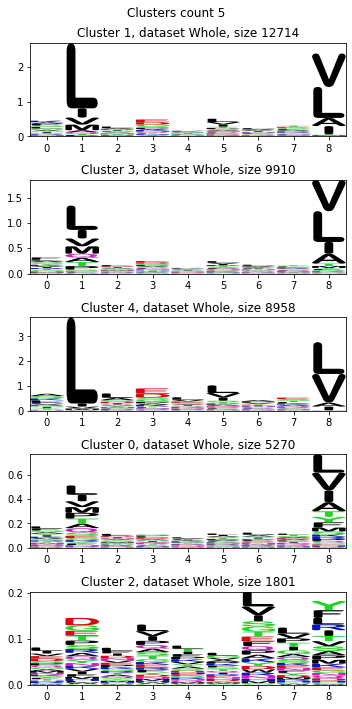

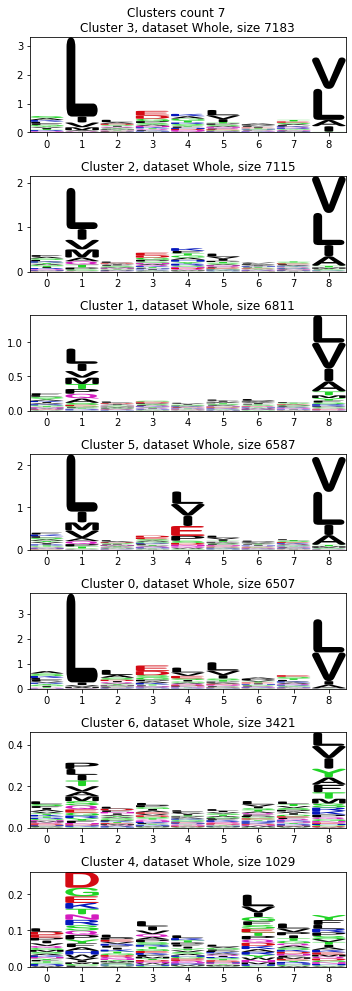

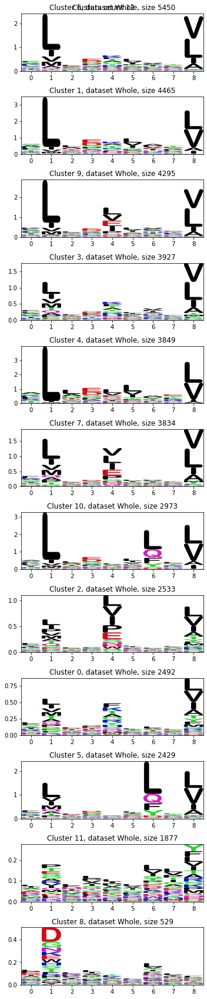

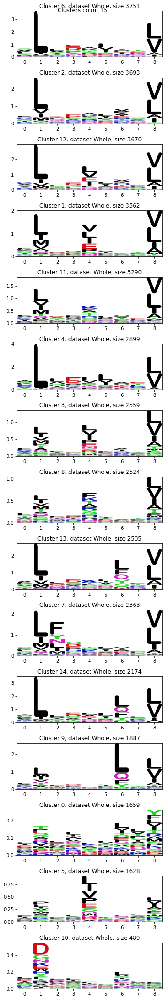

In [39]:
#binding
for cluster_count in cluster_counts:
    result = per_cluster_count_result_repr[cluster_count]['mb']
    fig = logo_pictures_for_clusters(result, title=f"Clusters count {cluster_count}")

unique_labels after sorting [1, 3, 4, 0, 2]
 label 1
 label 3
 label 4
 label 0
 label 2

unique_labels after sorting [2, 4, 3, 6, 0, 1, 5]
 label 2
 label 4
 label 3
 label 6
 label 0
 label 1
 label 5

unique_labels after sorting [0, 8, 10, 6, 3, 1, 11, 7, 9, 5, 4, 2]
 label 0
 label 8
 label 10
 label 6
 label 3
 label 1
 label 11
 label 7
 label 9
 label 5
 label 4
 label 2

unique_labels after sorting [4, 8, 7, 6, 3, 11, 1, 5, 10, 13, 0, 9, 2, 14, 12]
 label 4
 label 8
 label 7
 label 6
 label 3
 label 11
 label 1
 label 5
 label 10
 label 13
 label 0
 label 9
 label 2
 label 14
 label 12



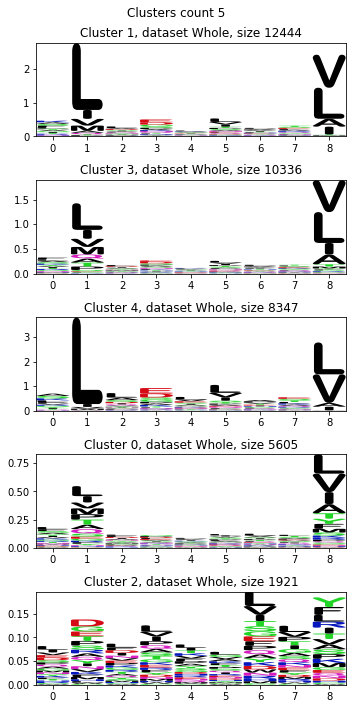

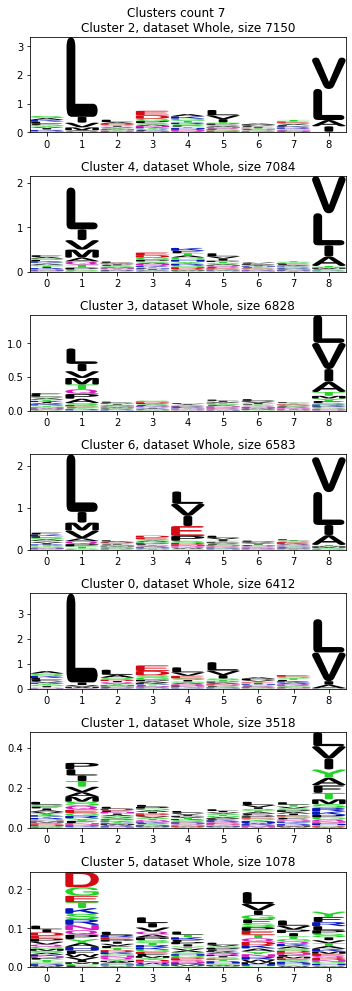

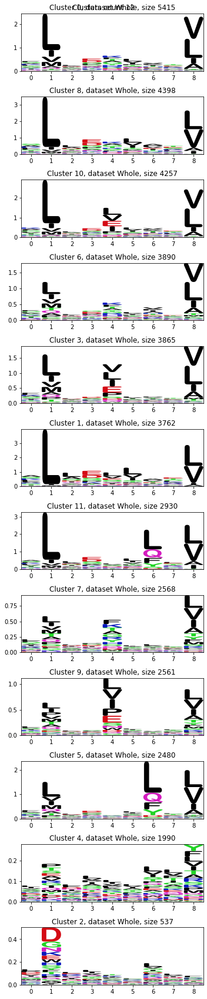

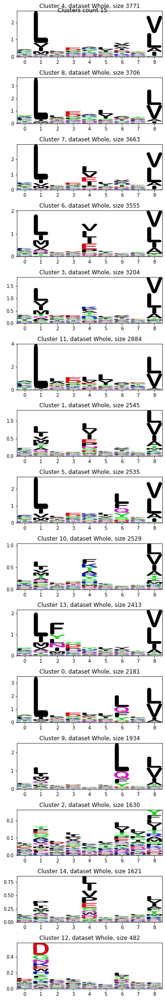

In [41]:
#binding 
# PCA simple
for cluster_count in cluster_counts:
    result = per_cluster_count_result_pca[cluster_count]['mb']
    fig = logo_pictures_for_clusters(result, title=f"Clusters count {cluster_count}")

unique_labels after sorting [3, 0, 2, 1, 4]
 label 3
 label 0
 label 2
 label 1
 label 4

unique_labels after sorting [3, 2, 4, 1, 6, 0, 5]
 label 3
 label 2
 label 4
 label 1
 label 6
 label 0
 label 5

unique_labels after sorting [1, 2, 10, 4, 8, 6, 0, 11, 7, 3, 5, 9]
 label 1
 label 2
 label 10
 label 4
 label 8
 label 6
 label 0
 label 11
 label 7
 label 3
 label 5
 label 9

unique_labels after sorting [5, 6, 2, 10, 1, 9, 4, 12, 8, 13, 14, 0, 7, 3, 11]
 label 5
 label 6
 label 2
 label 10
 label 1
 label 9
 label 4
 label 12
 label 8
 label 13
 label 14
 label 0
 label 7
 label 3
 label 11



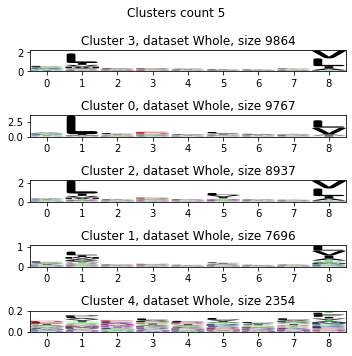

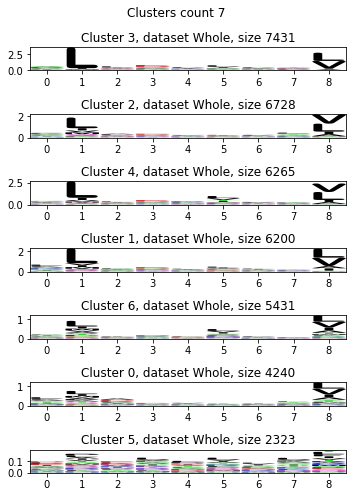

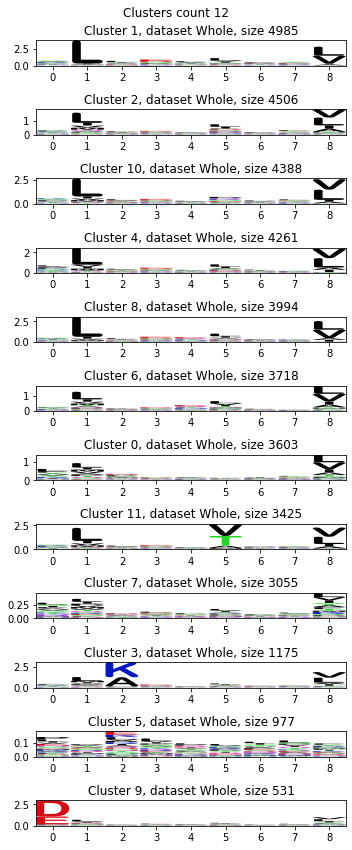

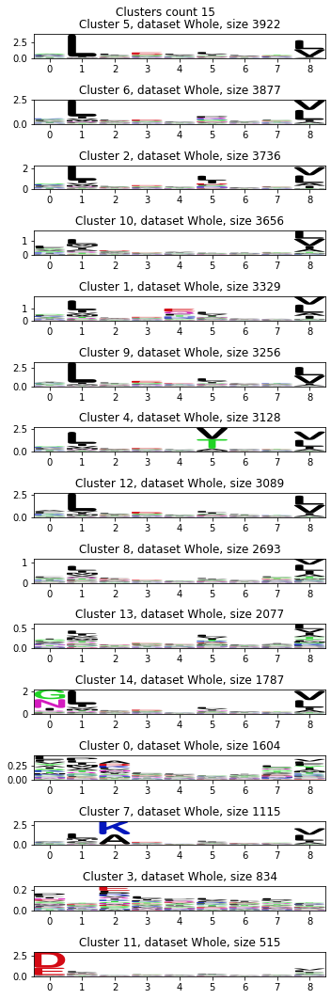

In [31]:
#binding 
# PCA pca_w
for cluster_count in cluster_counts:
    result = per_cluster_count_result_pca_w[cluster_count]['mb']
    fig = logo_pictures_for_clusters(result, title=f"Clusters count {cluster_count}")

unique_labels after sorting [0, 1, 2]
 label 0  label 0 dataset Train_db
 label 0 dataset Generated_di


KeyboardInterrupt: 

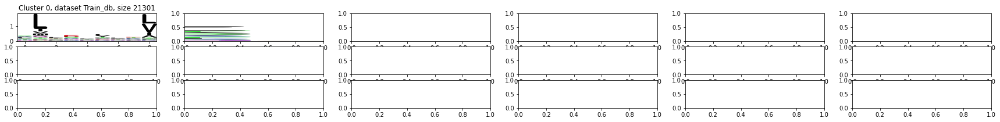

In [152]:
#binding 
# PCA pca_w
for cluster_count in cluster_counts:
    result = per_cluster_count_result_pca_w[cluster_count]['mb']
    fig = logo_pictures_for_clusters(result, title=f"Clusters count {cluster_count}", per_dataset=True)


# Only  binding vs immunogenic

unique_labels after sorting [1, 4, 3, 2, 0]
 label 1
 label 1 dataset Binding_data
 label 1 dataset Immunogenic_data
 label 4
 label 4 dataset Binding_data
 label 4 dataset Immunogenic_data
 label 3
 label 3 dataset Binding_data
 label 3 dataset Immunogenic_data
 label 2
 label 2 dataset Binding_data
 label 2 dataset Immunogenic_data
 label 0
 label 0 dataset Binding_data
 label 0 dataset Immunogenic_data

unique_labels after sorting [5, 0, 2, 4, 1, 3, 6]
 label 5
 label 5 dataset Binding_data
 label 5 dataset Immunogenic_data
 label 0
 label 0 dataset Binding_data
 label 0 dataset Immunogenic_data
 label 2
 label 2 dataset Binding_data
 label 2 dataset Immunogenic_data
 label 4
 label 4 dataset Binding_data
 label 4 dataset Immunogenic_data
 label 1
 label 1 dataset Binding_data
 label 1 dataset Immunogenic_data
 label 3
 label 3 dataset Binding_data
 label 3 dataset Immunogenic_data
 label 6
 label 6 dataset Binding_data
 label 6 dataset Immunogenic_data

unique_labels after sorting 

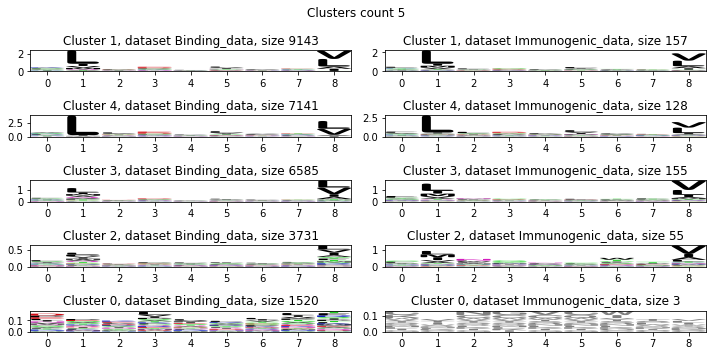

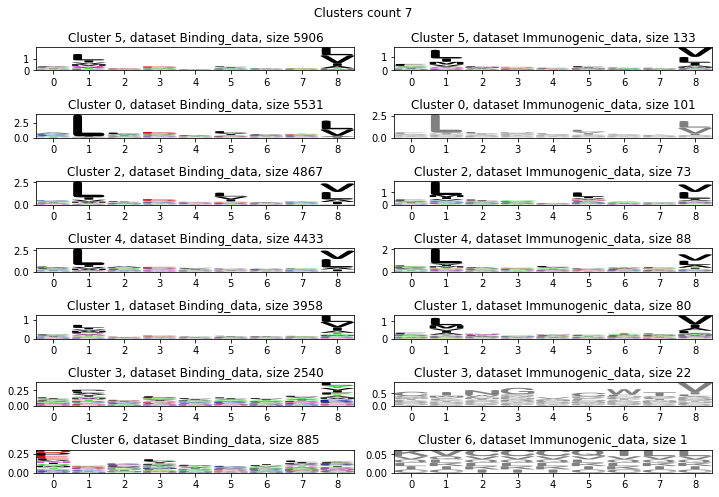

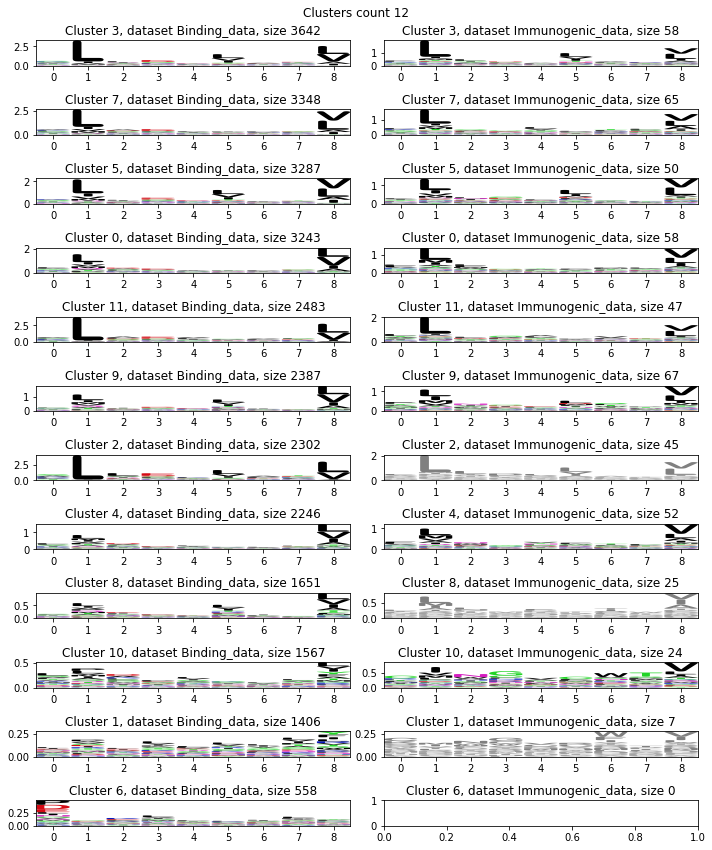

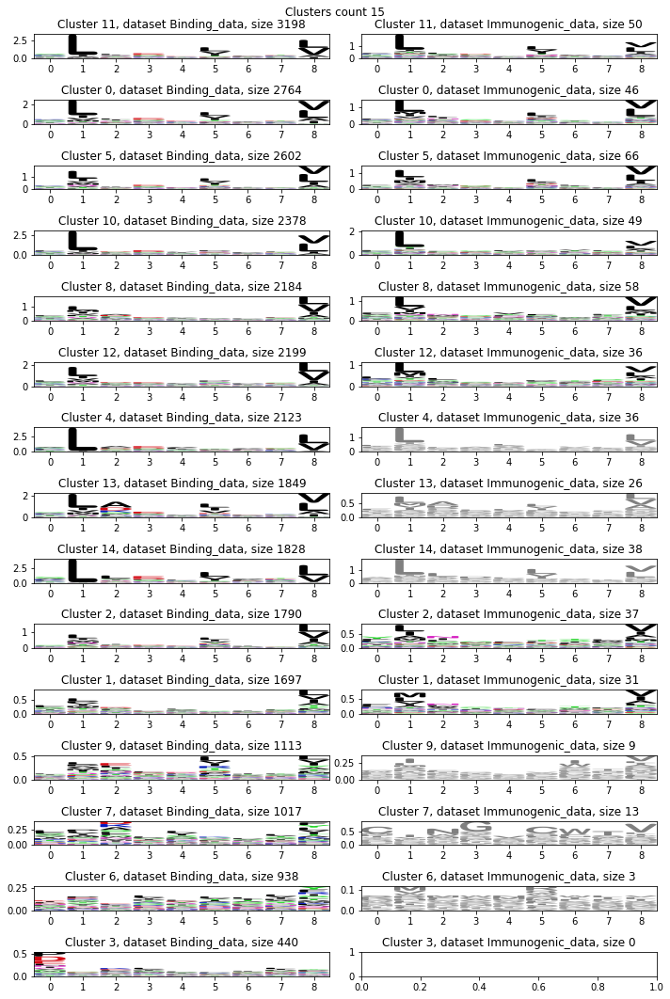

In [32]:
for cluster_count in cluster_counts:
    mb_df = per_cluster_count_result_repr[cluster_count]['mb']
    mb_df.loc[mb_df['dataset'].str.endswith('db'), 'general_dataset'] = 'Binding_data'
    mb_df.loc[mb_df['dataset'].str.endswith('di'), 'general_dataset'] = 'Immunogenic_data'

    #don't use Generated data here
    mb_df = mb_df.loc[~mb_df['dataset'].str.startswith('Generated')]

    fig = logo_pictures_for_clusters(mb_df, title=f"Clusters count {cluster_count}", per_dataset=True, hue_column='general_dataset')


unique_labels after sorting [0, 3, 2, 1, 4]
 label 0
 label 0 dataset Binding_data
 label 0 dataset Immunogenic_data
 label 3
 label 3 dataset Binding_data
 label 3 dataset Immunogenic_data
 label 2
 label 2 dataset Binding_data
 label 2 dataset Immunogenic_data
 label 1
 label 1 dataset Binding_data
 label 1 dataset Immunogenic_data
 label 4
 label 4 dataset Binding_data
 label 4 dataset Immunogenic_data

unique_labels after sorting [3, 2, 4, 1, 6, 0, 5]
 label 3
 label 3 dataset Binding_data
 label 3 dataset Immunogenic_data
 label 2
 label 2 dataset Binding_data
 label 2 dataset Immunogenic_data
 label 4
 label 4 dataset Binding_data
 label 4 dataset Immunogenic_data
 label 1
 label 1 dataset Binding_data
 label 1 dataset Immunogenic_data
 label 6
 label 6 dataset Binding_data
 label 6 dataset Immunogenic_data
 label 0
 label 0 dataset Binding_data
 label 0 dataset Immunogenic_data
 label 5
 label 5 dataset Binding_data
 label 5 dataset Immunogenic_data

unique_labels after sorting 

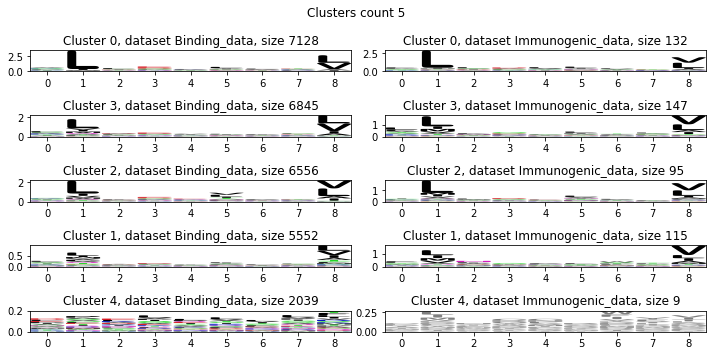

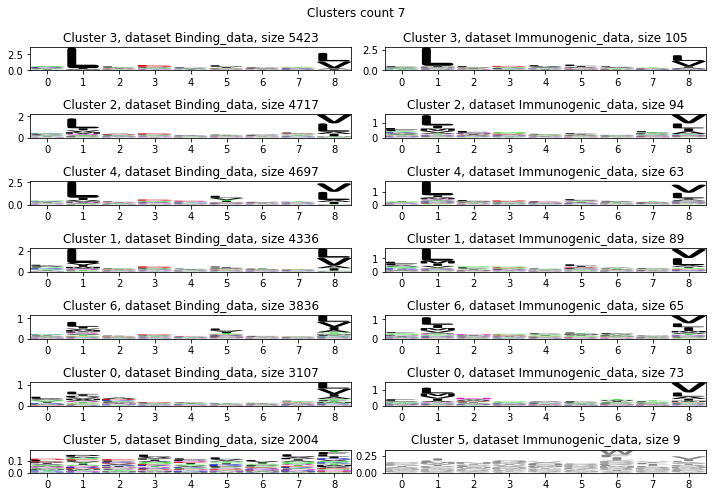

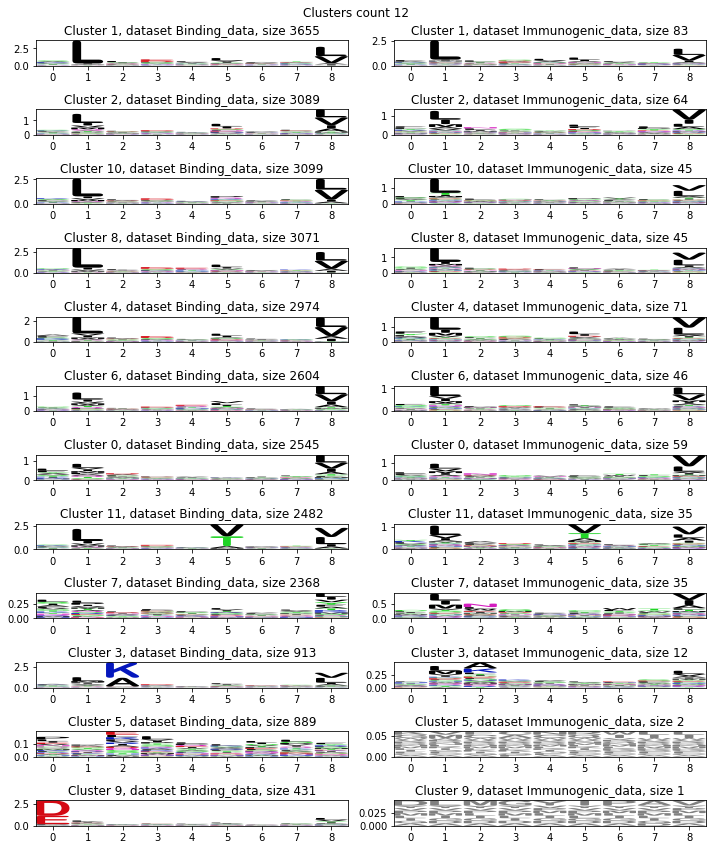

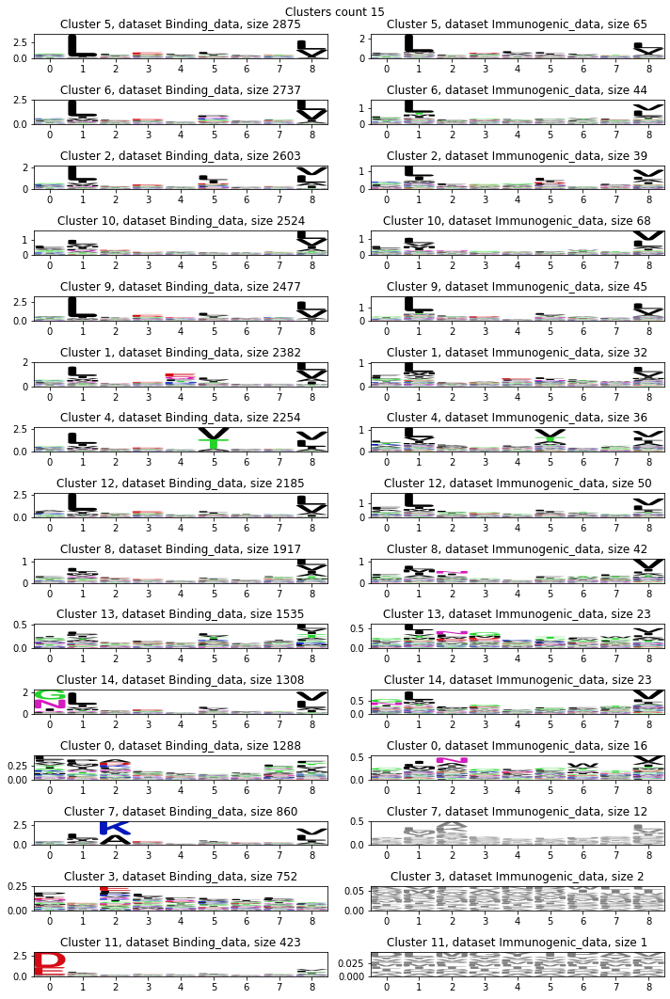

In [33]:
for cluster_count in cluster_counts:
    mb_df = per_cluster_count_result_pca_w[cluster_count]['mb']
    mb_df.loc[mb_df['dataset'].str.endswith('db'), 'general_dataset'] = 'Binding_data'
    mb_df.loc[mb_df['dataset'].str.endswith('di'), 'general_dataset'] = 'Immunogenic_data'

    #don't use Generated data here
    mb_df = mb_df.loc[~mb_df['dataset'].str.startswith('Generated')]

    fig = logo_pictures_for_clusters(mb_df, title=f"Clusters count {cluster_count}", per_dataset=True, hue_column='general_dataset')


## Plot PCA plots

In [45]:
per_cluster_count_result_repr[12]['mb']

path_index,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,label,dataset,general_dataset
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAGRKTL,-28.209427,-28.919583,-25.545563,-28.119677,-26.255719,-28.516574,-29.730464,-30.003148,-29.828256,-31.291776,...,-32.231224,-32.503908,-29.870289,-27.206425,-27.916581,-30.160919,-30.871075,9,Train_db,Binding_data
AAAAGWQTL,-30.942644,-30.526648,-28.278780,-30.852895,-27.862784,-30.123639,-28.090818,-27.237349,-28.763412,-28.525977,...,-30.591577,-29.738109,-32.603507,-29.939643,-29.523647,-32.894136,-32.478140,4,Train_db,Binding_data
AAAAKVPEV,-25.953146,-25.770263,-23.289282,-26.255000,-23.106399,-25.758858,-26.701358,-26.081003,-28.861440,-28.090068,...,-29.202117,-28.581763,-27.614008,-24.950144,-24.767262,-27.904638,-27.721755,7,Train_db,Binding_data
AAAAPRAVA,-30.269978,-30.360934,-27.606114,-29.189570,-27.697070,-28.967267,-31.791015,-31.444499,-31.797062,-33.260582,...,-34.291775,-33.945259,-31.930840,-29.266976,-29.357933,-32.221470,-32.312426,8,Train_db,Binding_data
AAAATCALV,-29.627253,-29.718210,-26.963389,-30.579426,-27.054346,-30.357123,-26.716438,-26.369923,-30.452908,-29.047822,...,-29.217198,-28.870682,-31.288116,-28.624252,-28.715208,-31.578745,-31.669702,4,Train_db,Binding_data
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YVYDLTVPV,-26.900499,-26.552641,-25.653158,-27.464626,-25.305301,-26.803509,-27.606173,-26.820843,-30.008901,-27.618803,...,-26.757550,-25.972220,-29.189522,-27.942181,-27.594324,-27.210998,-26.863141,5,Generated_di,Immunogenic_data
YVYIDIPKL,-27.628057,-27.445175,-26.380716,-28.361564,-26.197834,-27.865422,-29.977754,-29.357399,-29.298666,-30.338130,...,-29.129130,-28.508776,-29.917080,-28.669739,-28.486857,-27.938556,-27.755674,5,Generated_di,Immunogenic_data
YVYKITYLL,-27.230169,-28.216622,-25.982829,-29.598865,-26.969282,-30.272059,-27.935844,-28.484824,-31.270599,-28.880501,...,-27.087221,-27.636201,-29.519192,-28.271851,-29.258304,-27.540669,-28.527122,0,Generated_di,Immunogenic_data


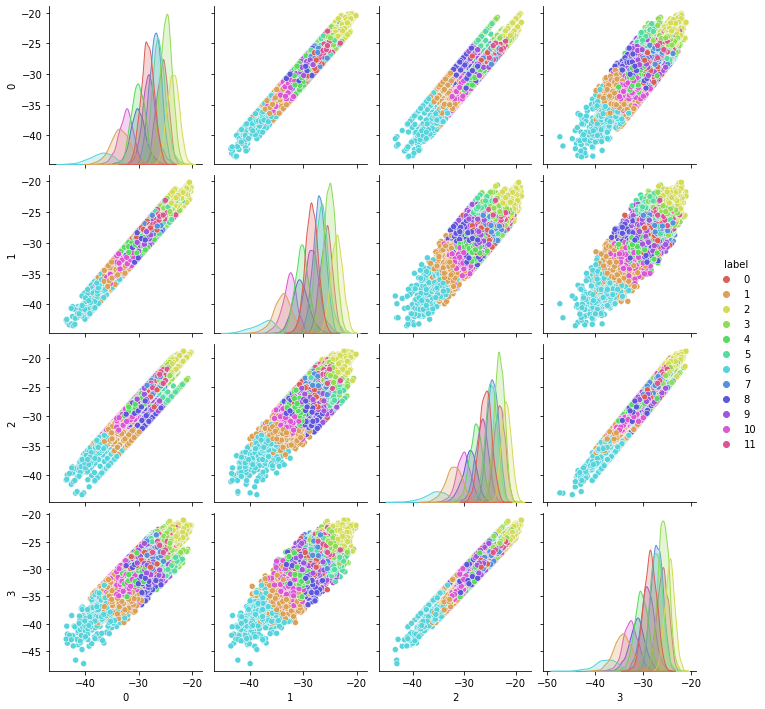

In [43]:
clusters_count = 12
sample_df = per_cluster_count_result_repr[clusters_count]['mb']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))


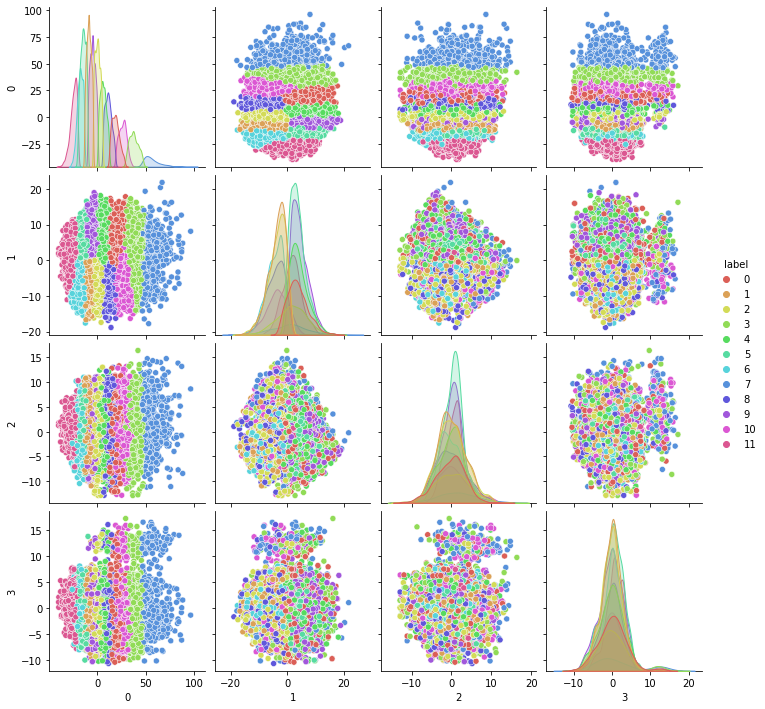

In [37]:
clusters_count = 12
sample_df = per_cluster_count_result_pca[clusters_count]['mb']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

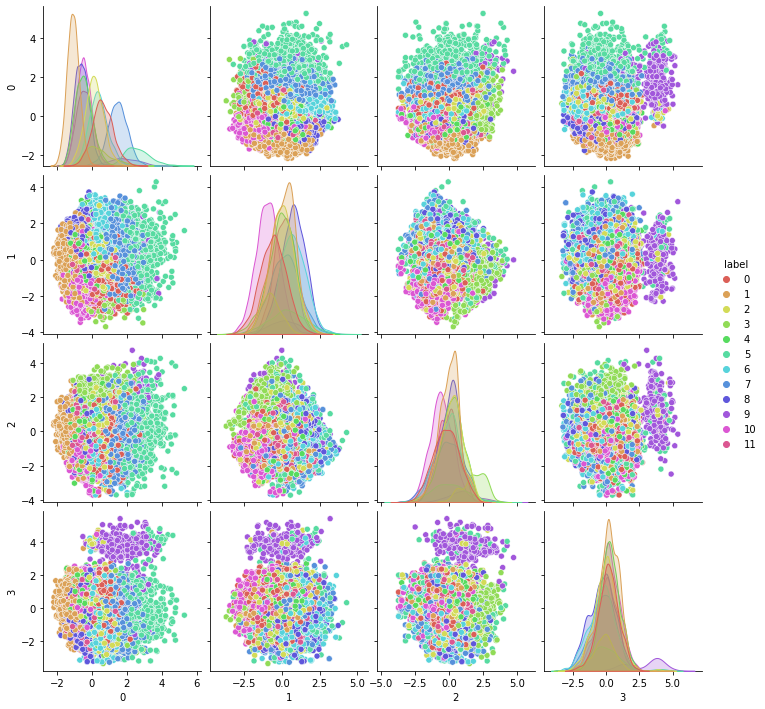

In [38]:
clusters_count = 12
sample_df = per_cluster_count_result_pca_w[clusters_count]['mb']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
df = pca_first_components.reset_index(drop=True)
colors = len(df['label'].unique())
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", colors))

<AxesSubplot:xlabel='0', ylabel='1'>

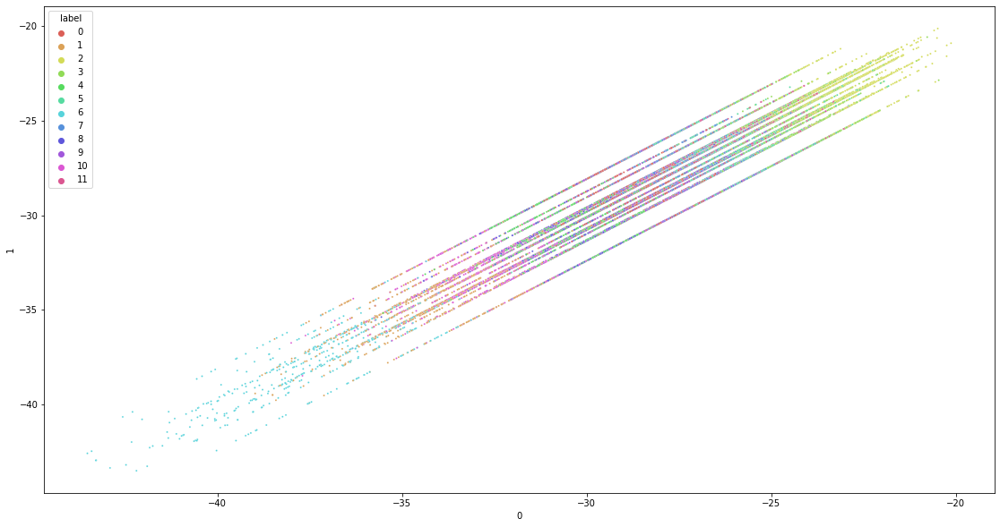

In [39]:
sample_df = per_cluster_count_result_repr[clusters_count]['mb']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
df = pca_first_components.reset_index(drop=True)
plt.figure(figsize=(19,10))
sns.scatterplot(data=df, x=0, y=1, hue='label', palette=sns.color_palette("hls", colors), s=4)

In [24]:
import umap
from sklearn.preprocessing import StandardScaler
from collections import defaultdict

def get_reducer(data,n_neighbors=15, n_components=2):
    reducer = umap.UMAP(n_neighbors=n_neighbors, n_components=n_components)
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    reducer.fit(scaled_data)
    return reducer, scaler

def get_umap_embedding(reducer, scaler,  data):
    scaled_data = scaler.fit_transform(data)
    umap_result = reducer.transform(scaled_data)
    df = pd.DataFrame(umap_result, index=data.index)
    return df


def collect_embeddings_with_pca_or_without(train_data, test_data, generated_data, scaler, reducer):
    if scaler and reducer :
        train_embedding = get_pca_embedding(pca, train_data)
        test_embedding = get_pca_embedding(pca, test_data)
        generated_embedding = get_pca_embedding(pca, generated_data)
    else:
        train_embedding = train_data.values
        test_embedding = test_data.values
        generated_embedding = generated_data.values

    train_df = pd.DataFrame(train_embedding)
    train_df['dataset'] = 'Train'
    test_df = pd.DataFrame(test_embedding)
    test_df['dataset'] = 'Test'
    generated_df = pd.DataFrame(generated_embedding)
    generated_df['dataset'] = 'Generated'
    total_embedding = pd.concat([train_df, test_df, generated_df])
    return total_embedding





def collect_embeddings(pivot_data_dict, scaler_b, reducer_b, scaler_i, reducer_i):
    embedding_dict = dict()
    for d_key in dataset_keys:
        embedding_dict[d_key] = dict()
        for s_key in source_keys:
            embedding_dict[d_key][s_key] = dict()
            data = pivot_data_dict[d_key][s_key]['mb'].drop(columns=["dataset", "label", "peptide"], errors='ignore')
            embedding_dict[d_key][s_key]['mb'] =  get_umap_embedding(reducer_b, scaler_b, data)
            data = pivot_data_dict[d_key][s_key]['mi'].drop(columns=["dataset", "label", "peptide"], errors='ignore')
            embedding_dict[d_key][s_key]['mi'] =  get_umap_embedding(reducer_i, scaler_i, data)
    return embedding_dict



def concat_embeddings_by_data_type(embedding_dict):
    total_embedding_data_lists = defaultdict(list)
    for d_key in dataset_keys:
        for s_key in source_keys:
            for m_key in model_keys:
                model_embedding = pd.DataFrame(embedding_dict[d_key][s_key][m_key])
                model_embedding['dataset'] = f"{d_key}_{s_key}"
                total_embedding_data_lists[m_key].append(model_embedding)
    total_embedding_data = {key:  pd.concat(total_embedding_data_lists[key]) for key in  total_embedding_data_lists}
    return total_embedding_data



def make_scatter_plot_sns(source_df, title, colors=None, hue_column='dataset' ):
    source_df = source_df.sample(frac=1)
    fig,ax = plt.subplots(figsize=(16, 10))
    sns.set_theme(style="dark")
    if colors is None:
        colors = define_pallete(source_df,hue_column )
    ax = sns.scatterplot(data=source_df, x=source_df.columns[0], y=source_df.columns[1], hue=hue_column,ax=ax, picker=4, s=10,
                         palette=colors)
    ax.set_title(title)

    peptides = source_df.index.values
    datasets = source_df['dataset'].values
    clusters = source_df['label'].values if hue_column == 'label' else datasets

    cursor =mplcursors.cursor(ax) # or just mplcursors.cursor()

    cursor.connect("add", lambda sel: sel.annotation.set_text(f"{peptides[sel.target.index]}, {datasets[sel.target.index]}, label {clusters[sel.target.index]}"))
    return fig


<AxesSubplot:xlabel='0', ylabel='1'>

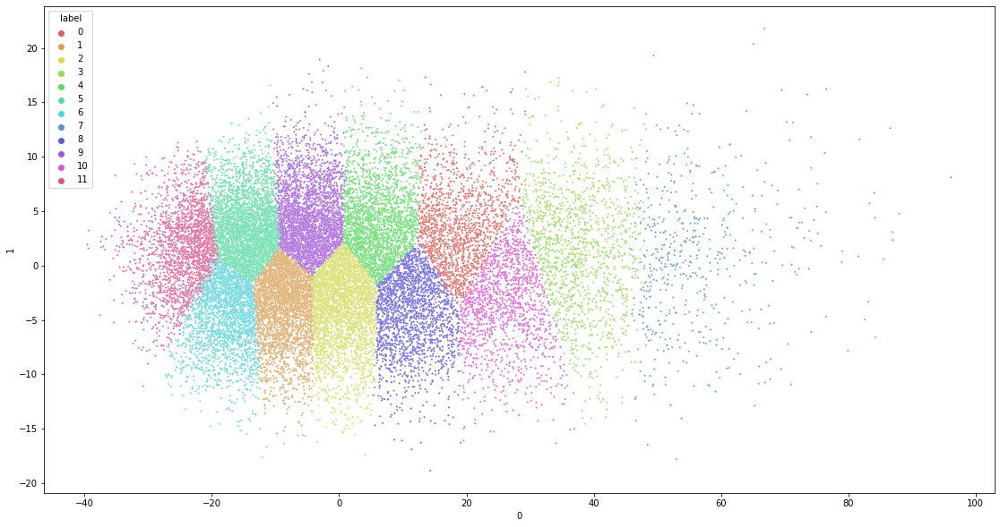

In [40]:
sample_df = per_cluster_count_result_pca[clusters_count]['mb']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
df = pca_first_components.reset_index(drop=True)
plt.figure(figsize=(19,10))
sns.scatterplot(data=df, x=0, y=1, hue='label', palette=sns.color_palette("hls", colors), s=4)

<AxesSubplot:xlabel='0', ylabel='1'>

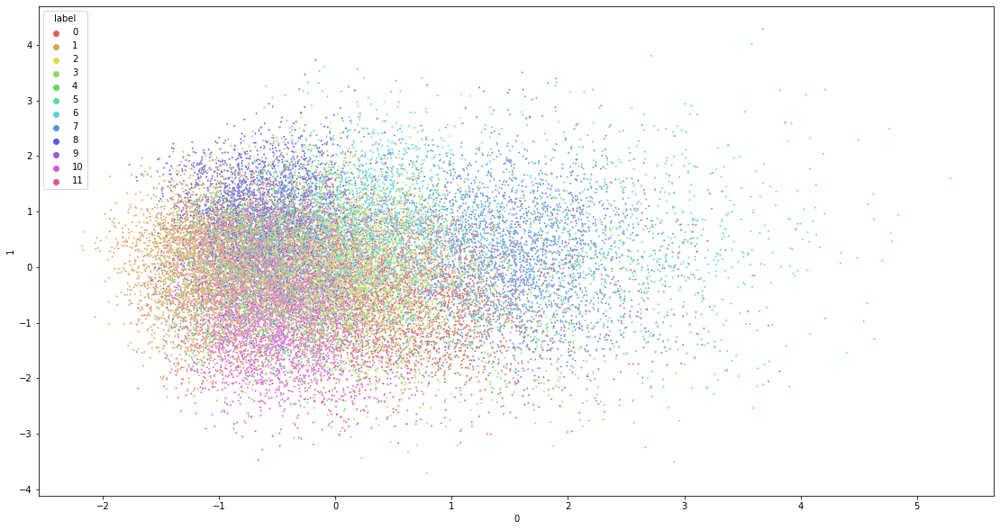

In [41]:
sample_df = per_cluster_count_result_pca_w[clusters_count]['mb']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
df = pca_first_components.reset_index(drop=True)
plt.figure(figsize=(19,10))
sns.scatterplot(data=df, x=0, y=1, hue='label', palette=sns.color_palette("hls", colors), s=4)

# Make UMAP object

In [ ]:
def collect_embeddings_with_pca_or_without(train_data, test_data, generated_data, pca):
    if pca:
        train_embedding = get_pca_embedding(pca, train_data)
        test_embedding = get_pca_embedding(pca, test_data)
        generated_embedding = get_pca_embedding(pca, generated_data)
    else:
        train_embedding = train_data.values
        test_embedding = test_data.values
        generated_embedding = generated_data.values

    train_df = pd.DataFrame(train_embedding)
    train_df['dataset'] = 'Train'
    test_df = pd.DataFrame(test_embedding)
    test_df['dataset'] = 'Test'
    generated_df = pd.DataFrame(generated_embedding)
    generated_df['dataset'] = 'Generated'
    total_embedding = pd.concat([train_df, test_df, generated_df])
    return total_embedding


def get_embedding_for_selected_models_using_pca(pca_b, pca_i):
    per_model_embedding_result = dict()
    for model_key in ['mb', 'mi']:
        if model_key == 'mb':
            model_name = selected_binding_model
            pca = pca_b
        else:
            model_name = selected_immune_model
            pca = pca_i
        train_repr = per_name_representation_train[model_name]['db']
        test_repr = per_name_representation_test[model_name]['db']
        generated_repr = per_name_representation_generated[model_name]['db']
        total_embedding_db = collect_embeddings_with_pca_or_without(train_repr, test_repr, generated_repr, pca)
        total_embedding_db['dataset'] = total_embedding_db['dataset'] + '_db'

        train_repr = per_name_representation_train[model_name]['di']
        test_repr = per_name_representation_test[model_name]['di']
        generated_repr = per_name_representation_generated[model_name]['di']
        total_embedding_di = collect_embeddings_with_pca_or_without(train_repr, test_repr, generated_repr, pca)
        total_embedding_di['dataset'] = total_embedding_di['dataset'] + '_di'

        total_embedding = pd.concat([total_embedding_db, total_embedding_di])
        per_model_embedding_result[model_key] = total_embedding
    return per_model_embedding_result

## Umap for 10 components

In [45]:
cluster_count = 12
model_key = 'mb'
n_components=3


total_model_df = per_cluster_count_result_repr[cluster_count]['mb']
train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
train_data = train_df.drop(columns=["dataset", "peptide", "label"],  errors='ignore').values
reducer_b, scaler_b = get_reducer(train_data, n_components=n_components)

total_model_df = per_cluster_count_result_repr[cluster_count]['mi']
train_df = total_model_df[total_model_df['dataset'] == f'Train_di']
train_data = train_df.drop(columns=["dataset", "peptide", "label"],  errors='ignore').values
reducer_i, scaler_i = get_reducer(train_data, n_components=n_components)

    
embedding_dict = collect_embeddings(pivot_data_dict, scaler_b, reducer_b, scaler_i, reducer_i )
total_embedding_data = concat_embeddings_by_data_type(embedding_dict)
total_embedding_data[model_key]['label'] = per_cluster_count_result_repr[cluster_count][model_key]['label'].values

In [46]:
df = total_embedding_data['mb']
df = df.reset_index(drop=True)

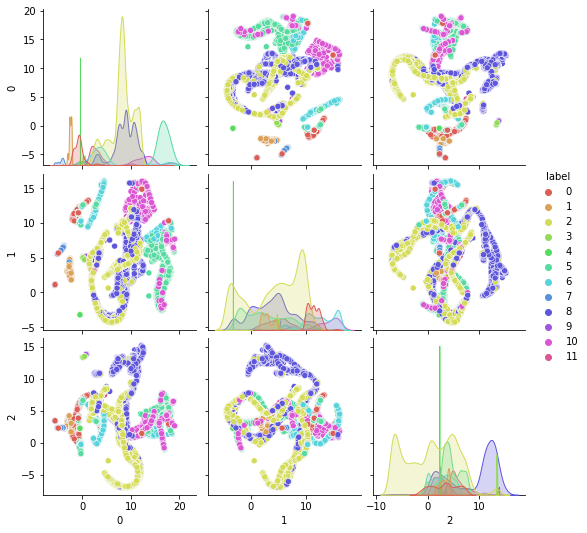

In [47]:
colors = len(df['label'].unique())
fig = sns.pairplot(df, hue='label', palette=sns.color_palette("hls", colors))


In [48]:
fig.savefig('pairplot_umap2.png', format="png", bbox_inches='tight', transparent=False)

In [89]:
cluster_count = 12
model_key = 'mb'
per_n_result = dict()
for n in (5, 10, 20, 50, 100, 200):
    print(f"n = {n}")
    total_model_df = per_cluster_count_result_repr[cluster_count]['mb']
    train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
    train_data = train_df.drop(columns=["dataset", "peptide", "label"],  errors='ignore').values
    reducer_b, scaler_b = get_reducer(train_data, n_neighbors=n)
    
    total_model_df = per_cluster_count_result_repr[cluster_count]['mi']
    train_df = total_model_df[total_model_df['dataset'] == f'Train_di']
    train_data = train_df.drop(columns=["dataset", "peptide", "label"],  errors='ignore').values
    reducer_i, scaler_i = get_reducer(train_data, n_neighbors=n)
    
    
    embedding_dict = collect_embeddings(pivot_data_dict, scaler_b, reducer_b, scaler_i, reducer_i )
    total_embedding_data = concat_embeddings_by_data_type(embedding_dict)
    total_embedding_data[model_key]['label'] = per_cluster_count_result_repr[cluster_count][model_key]['label'].values
    per_n_result[n] =  total_embedding_data[model_key]
    # target_df = total_embedding_data['mb']
    # # target_df = target_df[target_df['dataset'].str.endswith("db")]
    # fig = make_scatter_plot_sns(target_df, title="Binding model representation,neighbors {n}", hue_column='label')

    
    

n = 5
n = 10
n = 20
n = 50
n = 100
n = 200


### Want to use same pallete so use it

In [90]:
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import mplcursors

sample_total_embedding = total_embedding_data['mi']
def define_pallete(df, hue_column):
    unique_hue_values = sorted(df[hue_column].unique())
    source_pallete = sns.color_palette("hls", len(unique_hue_values))
    colors ={hue_value: source_pallete[i] for i, hue_value in enumerate(unique_hue_values)}
    return colors
colors = define_pallete(sample_total_embedding, 'dataset')

In [95]:
per_n_result[n]

,0,1,dataset,label
peptide,,,,
AAAAGWQTL,4.738283,4.275134,Train_db,0
AAAAKVPEV,6.646348,5.233228,Train_db,5
AAAANPLAL,-3.148399,-9.353266,Train_db,5
AAAATCALV,8.548706,-6.388693,Train_db,6
AAAAVIPTV,-2.866287,10.542775,Train_db,5
...,...,...,...,...
YVNGGPVFV,4.760615,4.244135,Generated_di,0
YVQDIPLSV,6.440584,5.090242,Generated_di,5
YVRHHLTWV,-7.050369,3.261048,Generated_di,9


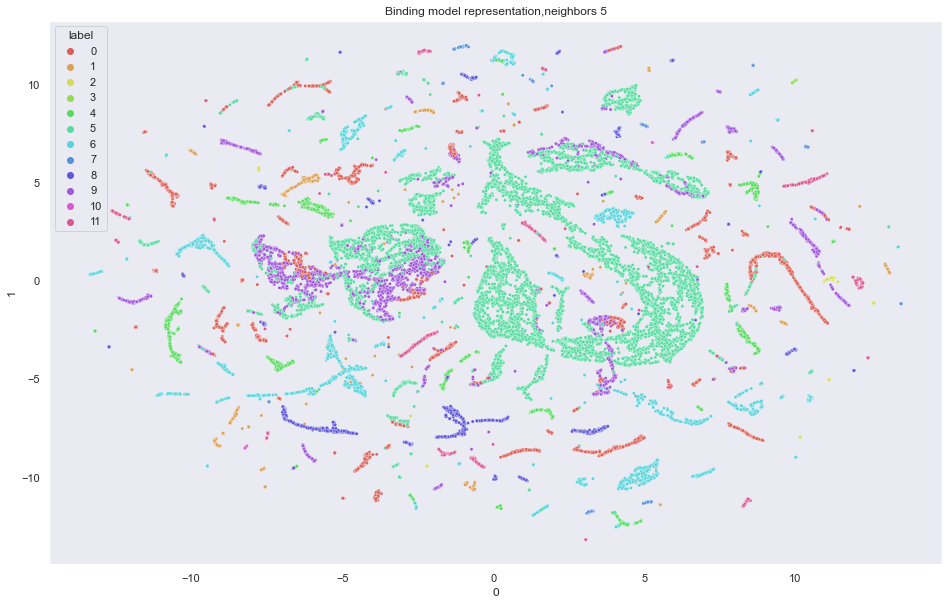

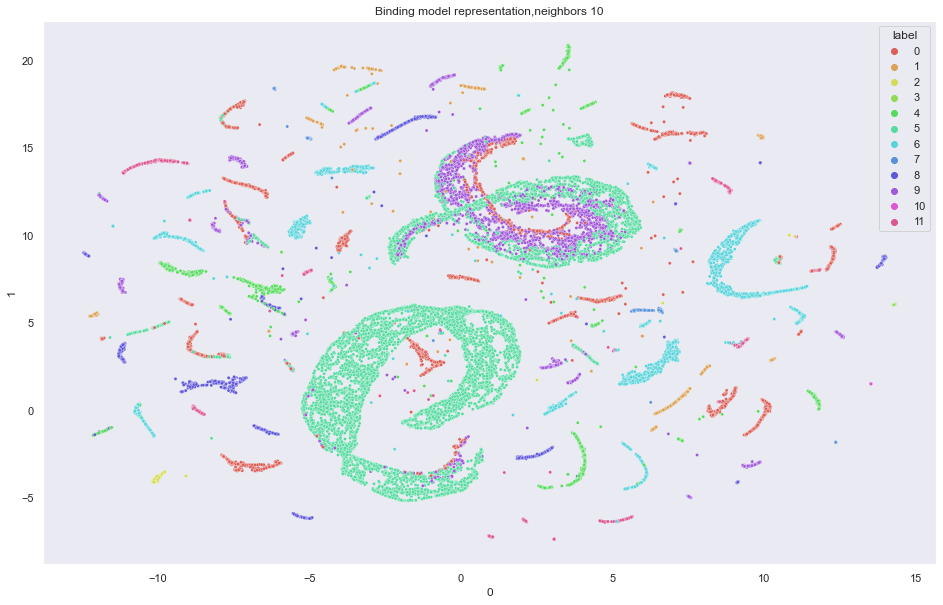

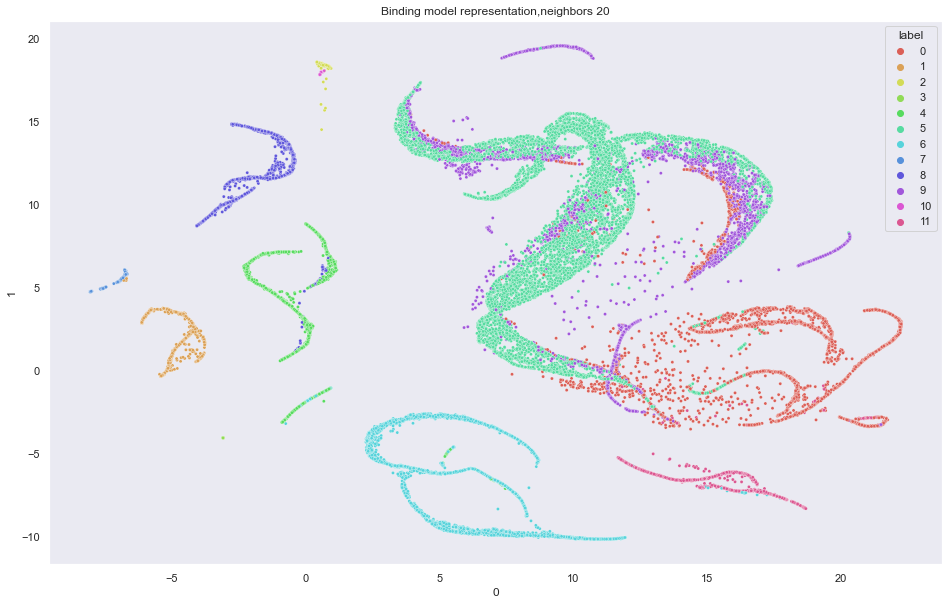

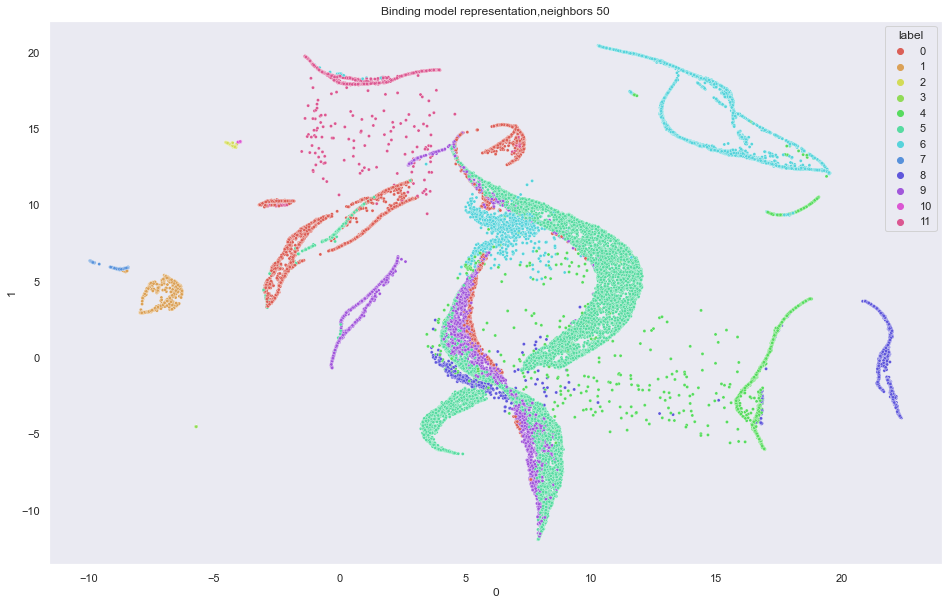

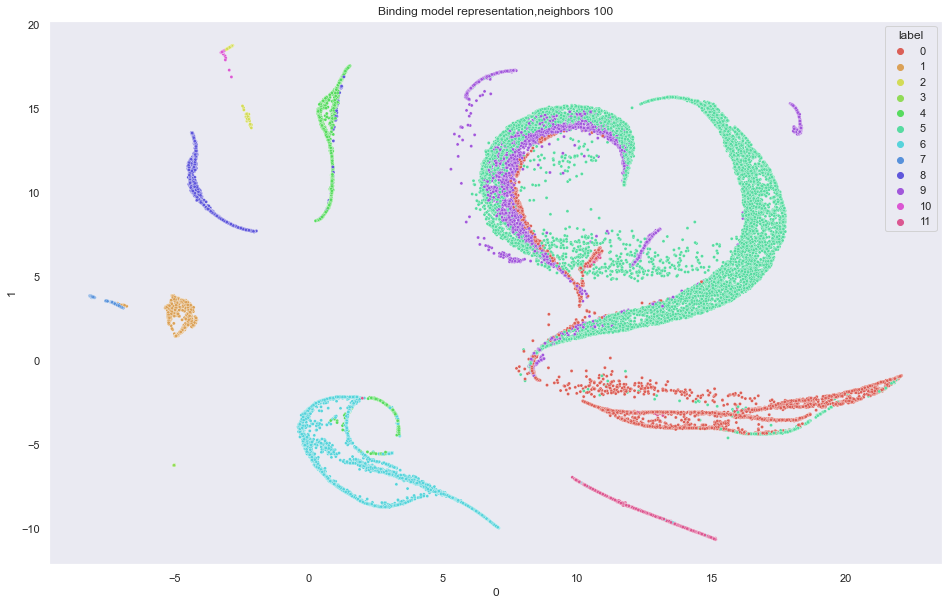

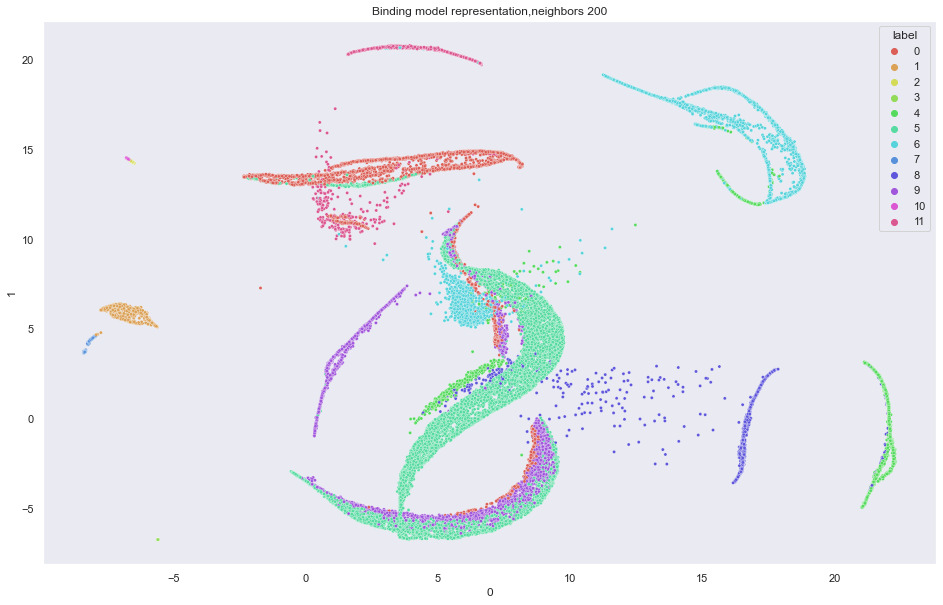

In [99]:
for n in (5, 10, 20, 50, 100, 200):
    target_df = per_n_result[n]
    target_df = target_df[target_df['dataset'].str.endswith("db")]
    target_df = target_df[~target_df['dataset'].str.startswith("Generated")]
    fig = make_scatter_plot_sns(target_df, title=f"Binding model representation,neighbors {n}", hue_column='label')
    

In [91]:




#define pallete

                
# def make_scatter_plot_matplotlib(source_df):
#     #plot
#     fig,ax = plt.subplots(figsize=(16, 10))
#     x =  source_df[0]
#     y =  source_df[1]
#     names = source_df['peptide'].values
#     color_choices = {"Train":0, "Test":1, "Generated":2}
#     color_to_dataset = {item:key for key, item in color_choices.items()}
#     c = source_df.dataset.map(color_choices).values
#     # took only color palette from sns
#     sc = plt.scatter(
#     x,
#     y,
#     s=14,
#     c=[sns.color_palette()[x] for x in c],
#     )
    
#     def update_annot(ind):
#         pos = sc.get_offsets()[ind["ind"][0]]
#         annot.xy = pos
#         hover_indexes = list(map(str,ind["ind"]))
#         hover_peptides = [names[n] for n in ind["ind"]]
#         hover_dataset = [color_to_dataset[c[n]] for n in ind["ind"]]
#         text = "\n".join([f"{idx}, {peptide}, {dataset}" for idx, peptide, dataset in zip(hover_indexes, hover_peptides,hover_dataset)])
#         annot.set_text(text)
#         annot.get_bbox_patch().set_facecolor(sns.color_palette()[c[ind["ind"][0]]])
#         annot.get_bbox_patch().set_alpha(0.4)

#     def hover(event):
#         vis = annot.get_visible()
#         if event.inaxes == ax:
#             cont, ind = sc.contains(event)
#             if cont:
#                 update_annot(ind)
#                 annot.set_visible(True)
#                 fig.canvas.draw_idle()
#             else:
#                 if vis:
#                     annot.set_visible(False)
#                     fig.canvas.draw_idle()
    
#     annot = ax.annotate("", xy=(0,0), xytext=(20,20),textcoords="offset points",
#                         bbox=dict(boxstyle="round", fc="w"),
#                         arrowprops=dict(arrowstyle="->"))
#     annot.set_visible(False)
#     #make hover behavior
#     fig.canvas.mpl_connect("motion_notify_event", hover)
#     fig.canvas.toolbar_visible = True
#     fig.canvas.header_visible = True
#     fig.canvas.resizable = True
    

#     legend_elements = [Line2D([0], [0], marker='o', color=sns.color_palette()[c_inx], label=label, markersize=15)
#                        for label, c_inx  in color_choices.items()]
#     plt.legend(handles=legend_elements)
#     plt.title('UMAP plot', fontsize=24)
#     return fig


def make_scatter_plot_sns(source_df, title, colors=None, hue_column='dataset' ):
    source_df = source_df.sample(frac=1)
    fig,ax = plt.subplots(figsize=(16, 10))
    sns.set_theme(style="dark")
    if colors is None:
        colors = define_pallete(source_df,hue_column )
    ax = sns.scatterplot(data=source_df, x=source_df.columns[0], y=source_df.columns[1], hue=hue_column,ax=ax, picker=4, s=10,
                         palette=colors)
    ax.set_title(title)

    peptides = source_df['peptide'].values
    datasets = source_df['dataset'].values
    clusters = source_df['label'].values if hue_column == 'label' else datasets

    cursor =mplcursors.cursor(ax) # or just mplcursors.cursor()

    cursor.connect("add", lambda sel: sel.annotation.set_text(f"{peptides[sel.target.index]}, {datasets[sel.target.index]}, label {clusters[sel.target.index]}"))
    return fig
    


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
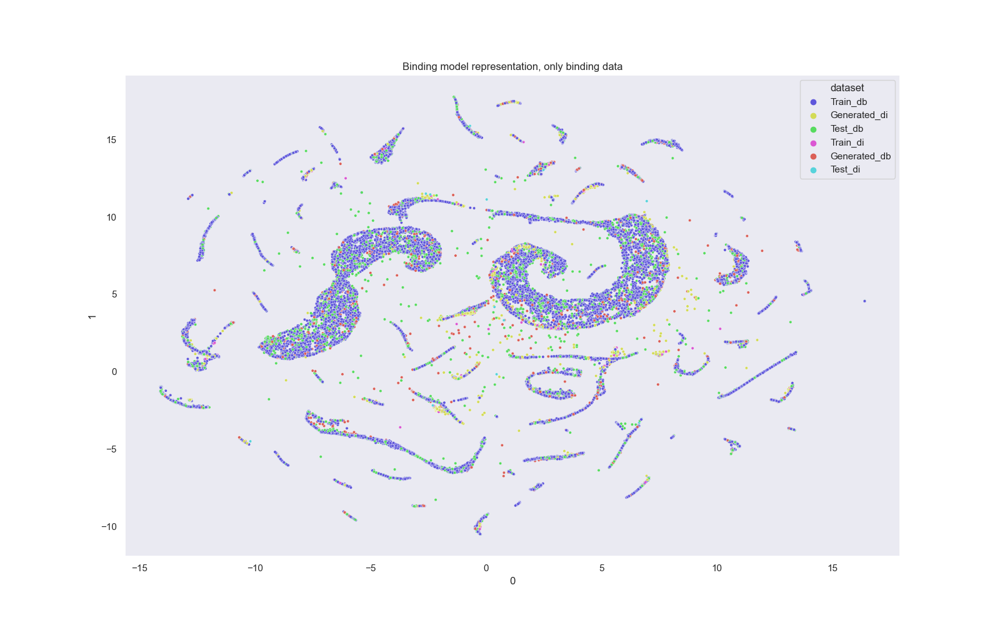

In [57]:
%matplotlib widget
target_df = total_embedding_data['mb']
# target_df = target_df[target_df['dataset'].str.endswith("db")]
fig = make_scatter_plot_sns(target_df, title="Binding model representation, only binding data", colors= colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
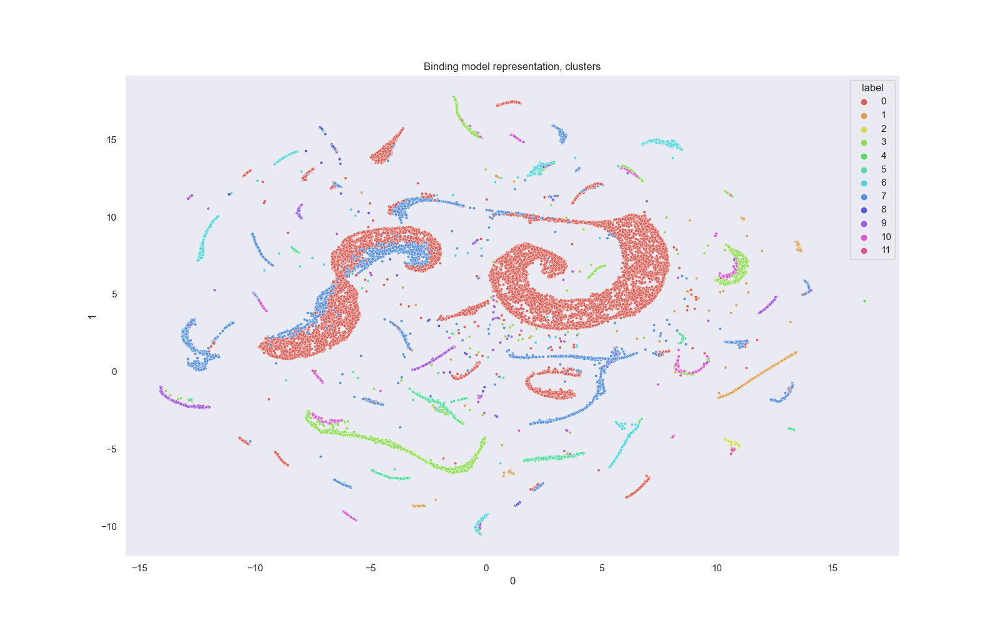

In [58]:
fig = make_scatter_plot_sns(target_df, title='Binding model representation, clusters', hue_column='label')

In [28]:
%%time
total_embedding_data = concat_embeddings_by_data_type(pivot_data_dict, embedding_dict)

In [29]:
sample_total_embedding = total_embedding_data['mi']
sample_total_embedding

,0,1,dataset,peptide
0,-2.515633,6.916670,Train_db,AAAAGRKTL
1,10.476819,-4.106772,Train_db,AAAAKVPEV
2,-8.027201,6.298792,Train_db,AAAANPLAL
3,10.526694,-4.103232,Train_db,AAAAPRAVA
4,10.472793,-4.086463,Train_db,AAAAVIPTV
...,...,...,...,...
1995,10.498105,6.986912,Generated_di,YVNCYDVLA
1996,15.612631,-3.809191,Generated_di,YVSEALNFA
1997,10.347188,12.951543,Generated_di,YVVETVHGL
1998,-2.567263,6.739117,Generated_di,YVYEGLTFI


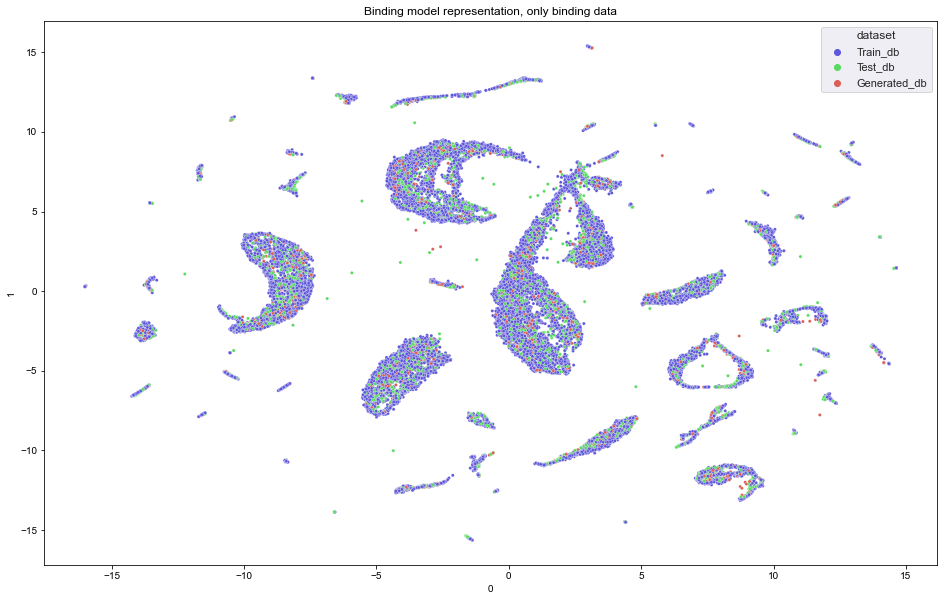

In [33]:
target_df = total_embedding_data['mb']
target_df = target_df[target_df['dataset'].str.endswith("db")]
fig = make_scatter_plot_sns(target_df, title="Binding model representation, only binding data", colors= colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
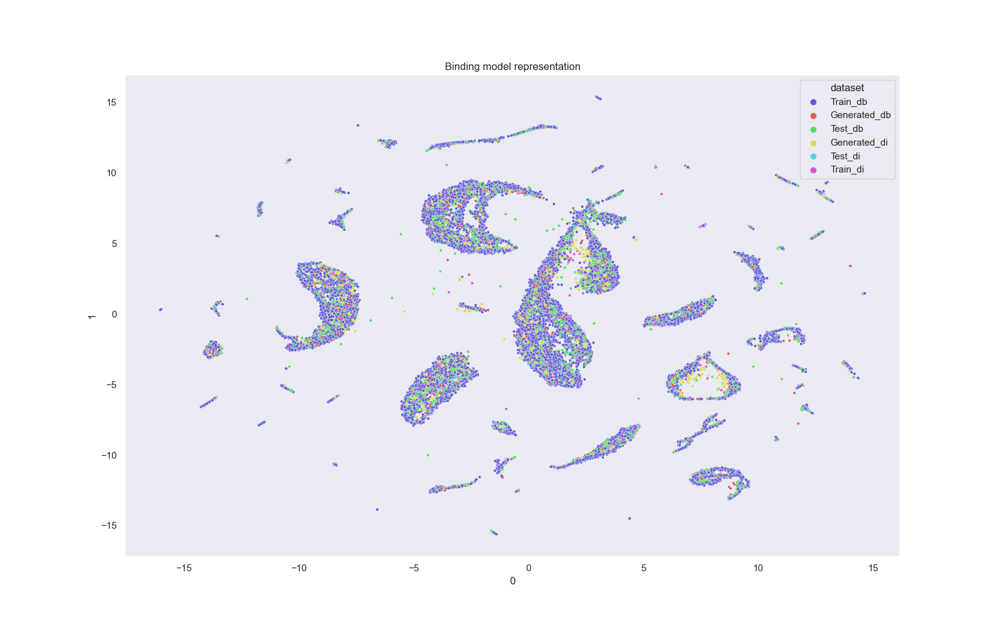

In [34]:
%matplotlib widget
# using
target_df = total_embedding_data['mb']
fig = make_scatter_plot_sns(target_df, title="Binding model representation", colors=colors)
# save_figure_to_file(fig, MODEL_PATH_USED, "umap_seaborn.png")

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
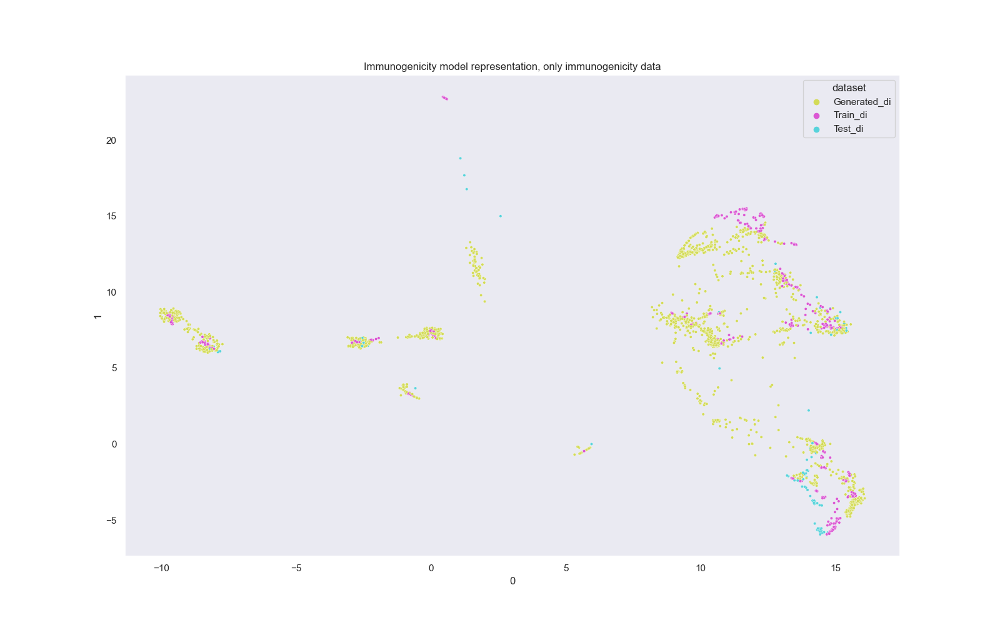

In [35]:
target_df = total_embedding_data['mi']
target_df = target_df[target_df['dataset'].str.endswith("di")]
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation, only immunogenicity data", colors=colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
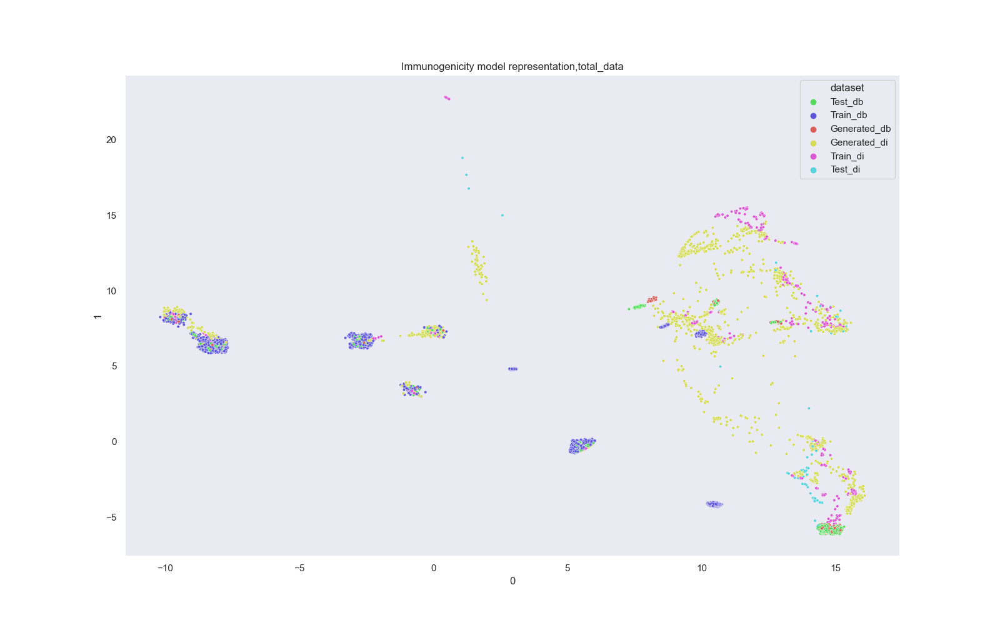

In [36]:
target_df = total_embedding_data['mi']
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation,total_data", colors=colors)

## Cluster result image

In [37]:
#Import required module
from sklearn.cluster import KMeans

def get_k_means_result(source_df, clusters_count):
    kmeans = KMeans(n_clusters= clusters_count)
    df = source_df[[0, 1]].values
    labels = kmeans.fit_predict(df)
    unique_labels = list(set(labels))
    clustered_df = source_df.copy()
    clustered_df['label'] = labels
    return clustered_df, unique_labels

In [38]:
clustered_df_b,  unique_labels_b = get_k_means_result( total_embedding_data['mb'], 40)
clustered_df_i, unique_labels_i = get_k_means_result( total_embedding_data['mi'], 15)


In [39]:
clustered_df_b

,0,1,dataset,peptide,label
0,1.521448,-1.030514,Train_db,AAAAGRKTL,35
1,-1.660873,4.334680,Train_db,AAAAKVPEV,3
2,-8.025420,2.730108,Train_db,AAAANPLAL,2
3,0.219125,0.200817,Train_db,AAAAPRAVA,8
4,-1.363073,4.463912,Train_db,AAAAVIPTV,3
...,...,...,...,...,...
1995,2.397912,4.243464,Generated_di,YVNCYDVLA,0
1996,-3.303624,-4.492368,Generated_di,YVSEALNFA,18
1997,7.156576,0.285080,Generated_di,YVVETVHGL,14
1998,-2.820658,-4.309101,Generated_di,YVYEGLTFI,18


# Plot clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
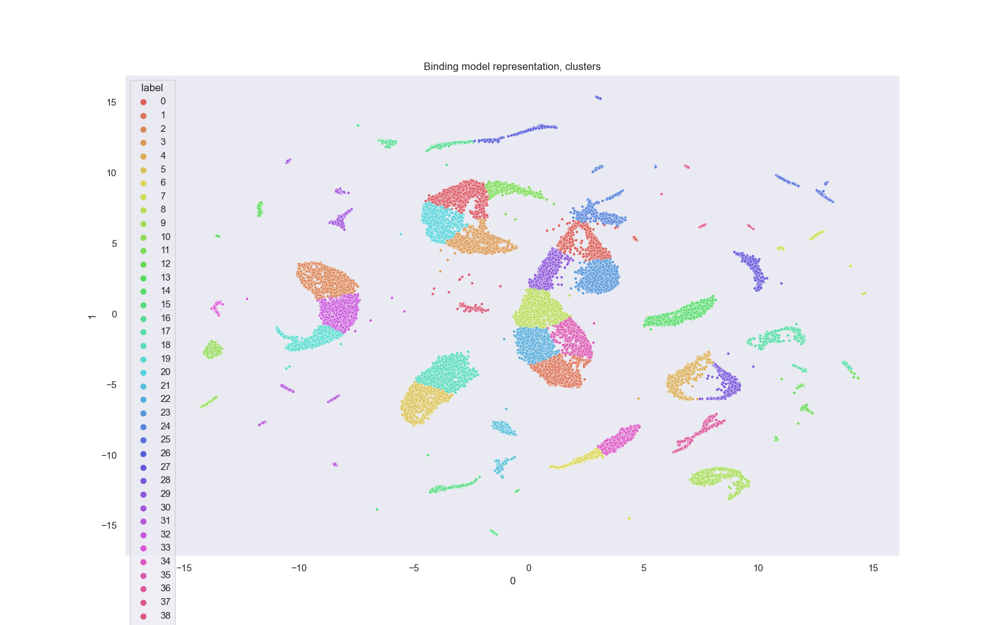

In [40]:
fig = make_scatter_plot_sns(clustered_df_b, title='Binding model representation, clusters', hue_column='label')

# save_figure_to_file(fig, MODEL_PATH_USED, "clustered_umap.png")

## Analyze clusters

In [41]:
import logomaker

def logo_pictures_for_clusters(source_clustered_df, per_dataset=False):
    if per_dataset:
        unique_datasets = set(source_clustered_df.dataset.values)
    else:
        unique_datasets = ["Whole"]
    unique_labels = set(source_clustered_df.label.values)
    fig, axes = plt.subplots(ncols=len(unique_datasets), nrows=len(unique_labels), figsize=[5*(len(unique_datasets)), 1*(len(unique_labels))])
    for cluster_index, cluster_label in enumerate(unique_labels):
        print(f" label {cluster_label}")
        for dataset_index, dataset_type in enumerate(unique_datasets):
            if per_dataset:
                print(f" label {cluster_label} dataset {dataset_type}")
                peptides = source_clustered_df[(source_clustered_df['label'] == cluster_label) & (source_clustered_df['dataset'] == dataset_type)]['peptide'].values
            else:
                peptides = source_clustered_df[source_clustered_df['label'] == cluster_label]['peptide'].values
            ax = axes[cluster_index][dataset_index] if per_dataset else axes[cluster_index]
            if len(peptides) > 0:
                matrix = logomaker.alignment_to_matrix(peptides)
                info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
                # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
                ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
            ax.set_title(f"Cluster {cluster_label}, dataset {dataset_type}, size {len(peptides)}")
    plt.tight_layout()

    return fig


 label 0
 label 1
 label 2
 label 3
 label 4
 label 5
 label 6
 label 7
 label 8
 label 9
 label 10
 label 11
 label 12
 label 13
 label 14
 label 15
 label 16
 label 17
 label 18
 label 19
 label 20
 label 21
 label 22
 label 23
 label 24
 label 25
 label 26
 label 27
 label 28
 label 29
 label 30
 label 31
 label 32
 label 33
 label 34
 label 35
 label 36
 label 37
 label 38
 label 39


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
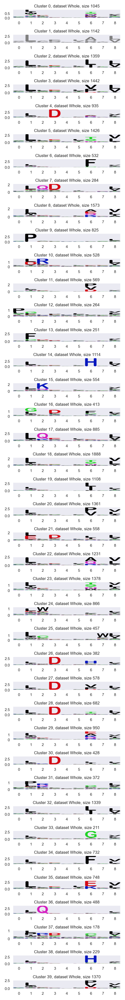

In [42]:
fig = logo_pictures_for_clusters(clustered_df_b)

In [ ]:
# if we want to plot per dataset logos (will take time for 40 clusters)
#fig = logo_pictures_for_clusters(clustered_df, per_dataset=True)


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
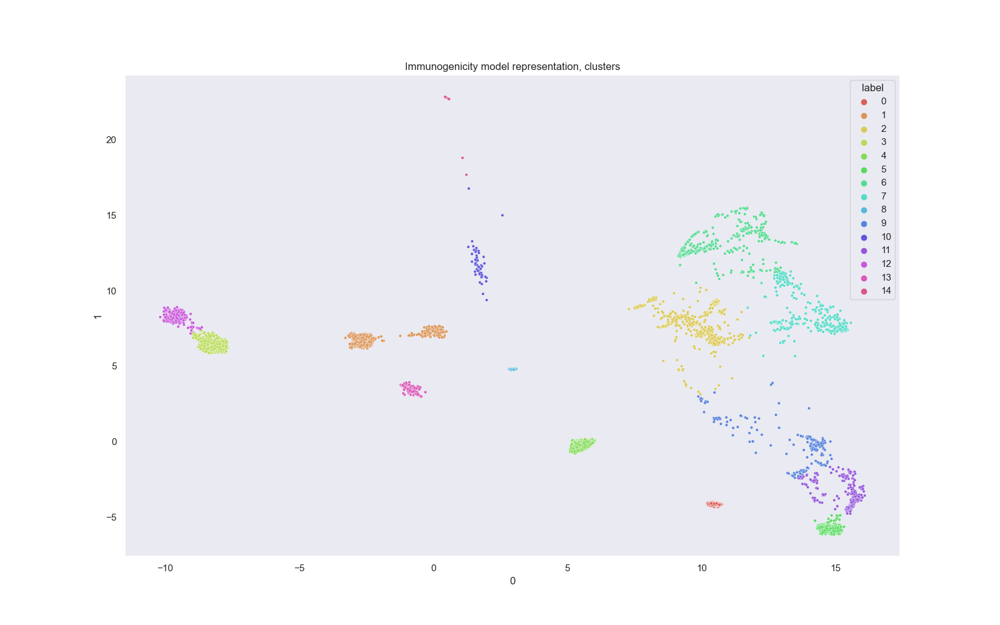

In [43]:
fig = make_scatter_plot_sns(clustered_df_i, title='Immunogenicity model representation, clusters', hue_column='label')

 label 0
 label 1
 label 2
 label 3
 label 4
 label 5
 label 6
 label 7
 label 8
 label 9
 label 10
 label 11
 label 12
 label 13
 label 14


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
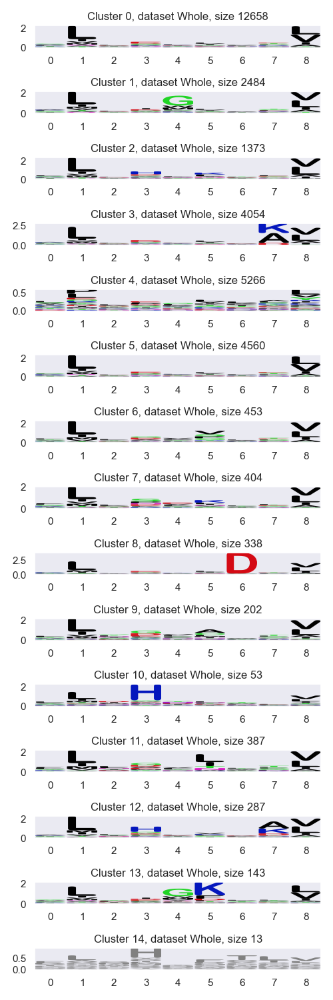

In [44]:
fig = logo_pictures_for_clusters(clustered_df_i)

# PCA

In [48]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA


def get_pca(df_concat, n_components=2, target_col="dataset"):
    X = df_concat.drop(columns=target_col, errors='ignore').values
    pca = PCA(n_components=n_components)
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_col="dataset"):
    X = data.drop(columns=target_col, errors='ignore').values
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result)
    return df


def collect_pca_embeddings(pivot_data_dict, pca_b, pca_i):
    embedding_dict = dict()
    for d_key in dataset_keys:
        embedding_dict[d_key] = dict()
        for s_key in source_keys:
            embedding_dict[d_key][s_key] = dict()
            embedding_dict[d_key][s_key]['mb'] =  get_pca_embedding(pca_b, pivot_data_dict[d_key][s_key]['mb'])
            embedding_dict[d_key][s_key]['mi'] =  get_pca_embedding(pca_i, pivot_data_dict[d_key][s_key]['mi'])
    return embedding_dict



In [47]:
pca_b = get_pca(pd.concat([pivot_data_dict['Train']['db']['mb']]))
pca_i = get_pca(pd.concat([pivot_data_dict['Train']['di']['mi']]))

Explained variation per principal component: [0.74719554 0.1535622 ]
Explained variation per principal component: [0.49233449 0.33703503]


In [49]:
embedding_dict = collect_pca_embeddings(pivot_data_dict, pca_b, pca_i)

In [52]:
total_embedding_data = concat_embeddings_by_data_type(pivot_data_dict, embedding_dict)

In [53]:
sample_total_embedding = total_embedding_data['mi']
sample_total_embedding

,0,1,dataset,peptide
0,98916.573145,-132081.998279,Train_db,AAAAGRKTL
1,-43707.006111,3223.989967,Train_db,AAAAKVPEV
2,129691.011375,87507.314244,Train_db,AAAANPLAL
3,-45654.516468,2166.666433,Train_db,AAAAPRAVA
4,-46756.720415,2106.155523,Train_db,AAAAVIPTV
...,...,...,...,...
1995,-46002.503391,2272.436504,Generated_di,YVNCYDVLA
1996,-46586.529811,1915.403967,Generated_di,YVSEALNFA
1997,-44646.161482,2302.773704,Generated_di,YVVETVHGL
1998,97973.198910,-133137.089099,Generated_di,YVYEGLTFI


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
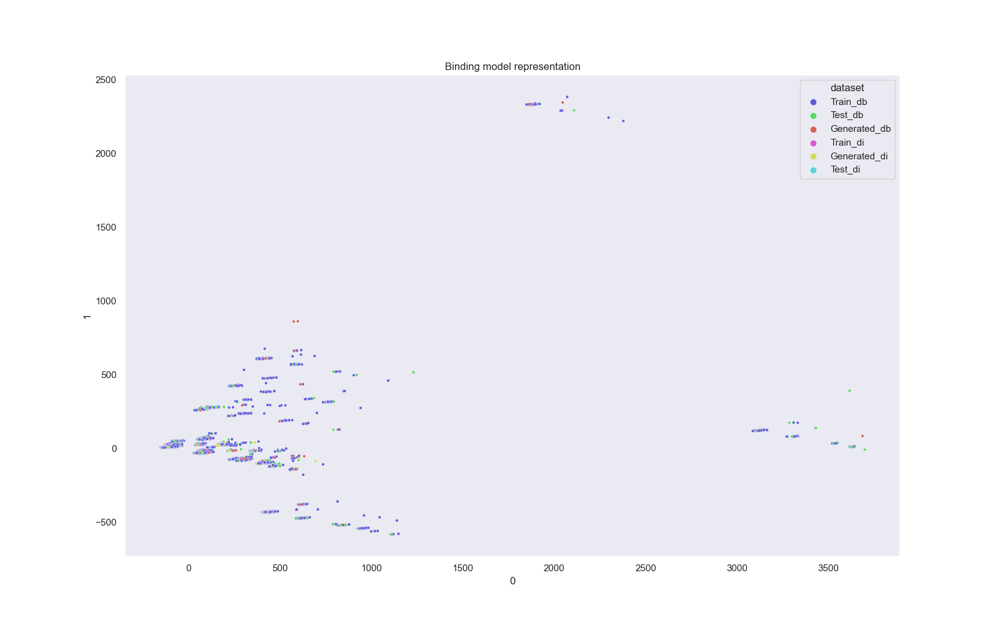

In [55]:
target_df = total_embedding_data['mb']
fig = make_scatter_plot_sns(target_df, title="Binding model representation", colors=colors)
# save_figure_to_file(fig, MODEL_PATH_USED, "umap_seaborn.png")

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
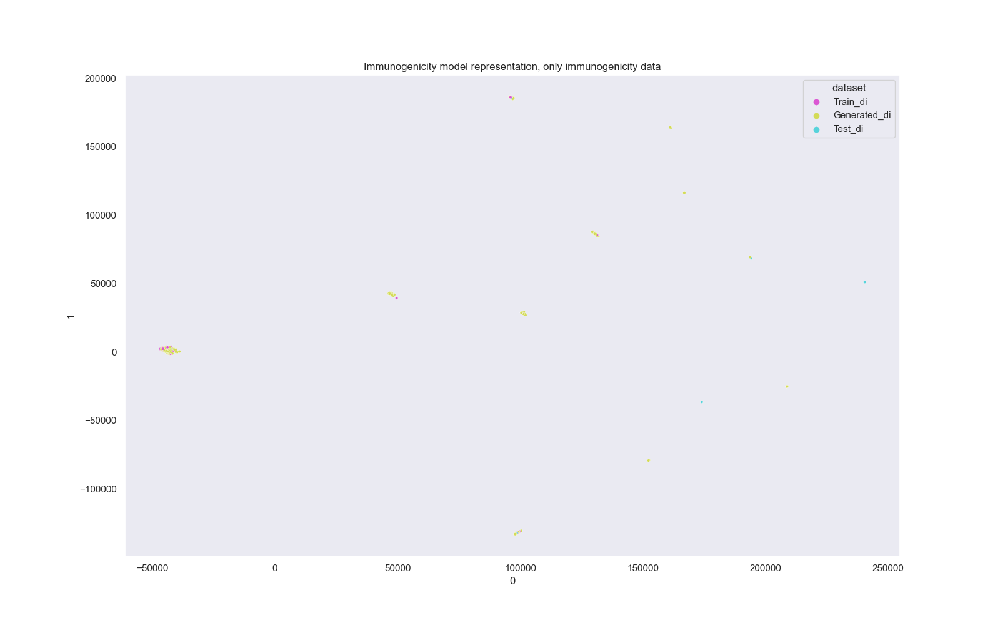

In [56]:
target_df = total_embedding_data['mi']
target_df = target_df[target_df['dataset'].str.endswith("di")]
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation, only immunogenicity data", colors=colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
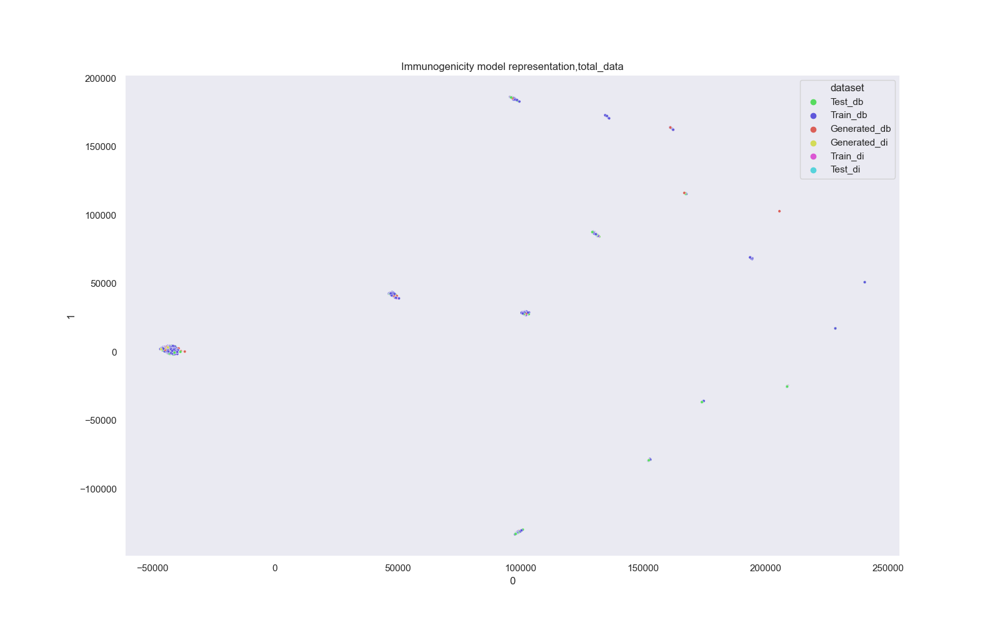

In [57]:
target_df = total_embedding_data['mi']
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation,total_data", colors=colors)

# Skip this section for now

### Cluster PCA

In [66]:
#Import required module
from sklearn.cluster import KMeans

#Initialize the class object
kmeans = KMeans(n_clusters= 8)
df = total_df[[0, 1]].values
#predict the labels of clusters.
labels = kmeans.fit_predict(df)

unique_labels = list(set(labels))
len(labels), unique_labels

(4981, [0, 1, 2, 3, 4, 5, 6, 7])

In [67]:
clustered_df = total_df.copy()
clustered_df['label'] = labels

In [68]:
clustered_df

,0,1,dataset,peptide,label
199,-71.734416,-5.084195,Test,KLAELPAA,6
1166,-60.455292,-14.125201,Generated,LVDQSVIL,6
394,-69.179509,-1.696582,Train,FLGPIIKA,6
1316,-43.954320,-8.189019,Train,LPVKQSGV,5
1809,180.215231,338.143473,Train,RPRPGTGL,3
...,...,...,...,...,...
365,-40.319295,2.931976,Generated,FPAAQISV,5
542,-30.725554,5.885188,Train,GVVLDDPV,5
1916,10.191973,6.185996,Generated,YAEYLIRV,0
2122,-40.140821,-3.358245,Train,VIQWELSI,5


## check plot with clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
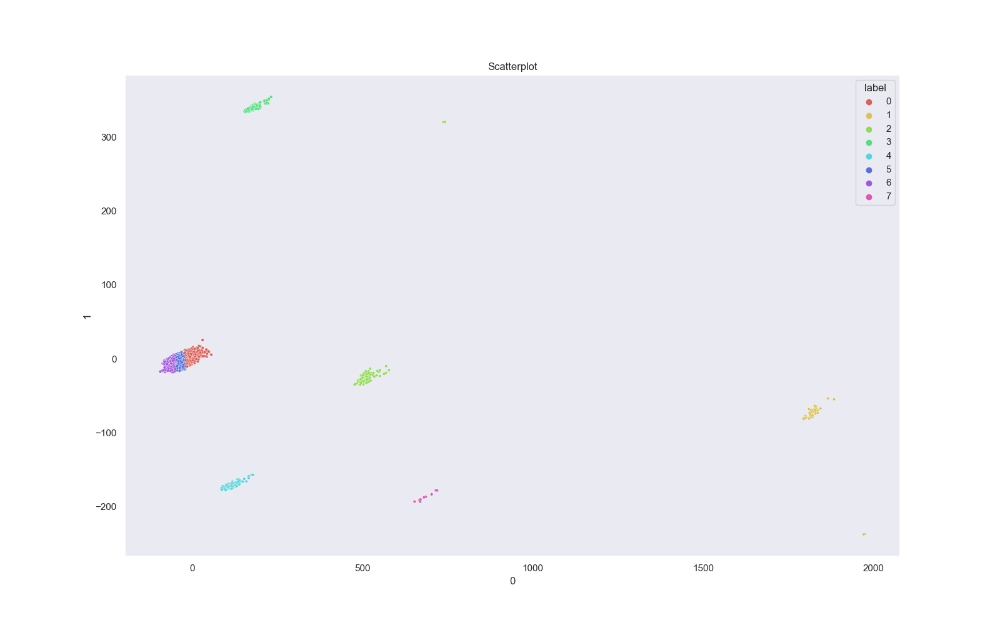

In [69]:
fig = make_scatter_plot_sns(clustered_df, hue_column='label')

save_figure_to_file(fig, MODEL_PATH_USED, "clustered_pca.png")


## Analyze clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
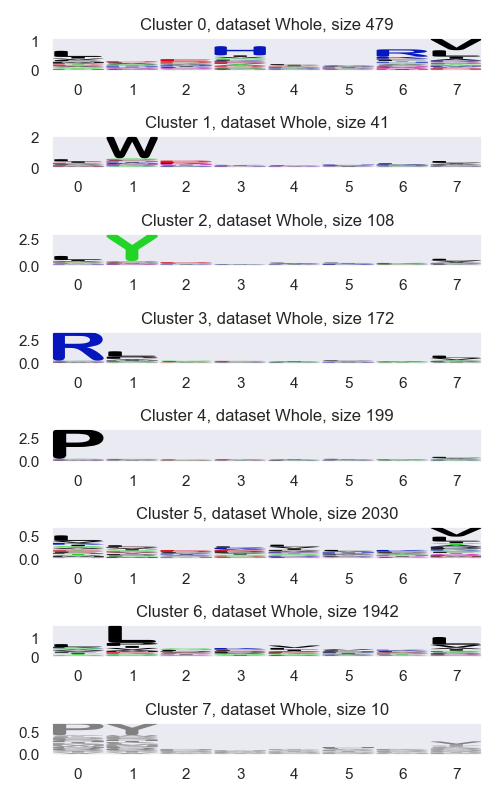

In [70]:
fig = logo_pictures_for_clusters(clustered_df)

# Cluster the original dataframe

In [92]:
pivot_data_dict['Train']['db']['mb']

path_index,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAGRKTL,-28.799758,-26.873801,-29.137366,-25.631248,-27.769312,-30.645407,-28.719449,-28.280842,-30.482373,-26.354884,...,-32.531042,-30.050343,-26.544226,-28.682290,-28.997001,-30.605085,-31.423599,-27.917481,-30.055545,-31.260566
AAAAKVPEV,-25.569554,-22.996404,-25.082871,-27.878426,-24.716205,-27.415202,-24.842052,-25.050637,-27.252169,-22.477487,...,-29.300838,-25.995849,-28.791404,-25.629183,-25.119604,-26.727688,-27.369105,-30.164660,-27.002438,-27.206071
AAAANPLAL,-25.359990,-26.405158,-24.771510,-29.608426,-28.226757,-27.205639,-28.250807,-24.841074,-27.042605,-25.886241,...,-29.091274,-25.684487,-30.521404,-29.139735,-28.528358,-30.136442,-27.057743,-31.894659,-30.512990,-26.894710
AAAAPRAVA,-29.344312,-28.327997,-30.250030,-28.291969,-28.655397,-31.189960,-30.173645,-28.825395,-31.026927,-27.809080,...,-33.075596,-31.163008,-29.204947,-29.568374,-30.451196,-32.059280,-32.536264,-30.578203,-30.941630,-32.373230
AAAAVIPTV,-24.904557,-23.155697,-25.242164,-28.037719,-24.051208,-26.750205,-25.001345,-24.385640,-26.587172,-22.636780,...,-28.635841,-26.155142,-28.950697,-24.964186,-25.278897,-26.886981,-27.528398,-30.323953,-26.337441,-27.365364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YYIFIPSKF,-36.559296,-35.122508,-35.723377,-36.103021,-37.191545,-37.822686,-36.385898,-33.619553,-36.588347,-32.182764,...,-41.214028,-33.292080,-33.671724,-34.760248,-32.964837,-39.777240,-34.800045,-35.179689,-36.268213,-33.565706
YYLNDLERI,-32.883258,-30.565938,-33.021655,-29.477976,-31.660659,-34.584965,-32.267645,-32.735375,-36.033117,-30.418054,...,-37.537990,-33.382218,-29.838539,-32.021222,-31.529075,-35.220670,-32.536640,-28.992961,-31.175644,-33.984793
YYNKVSTVF,-33.842061,-34.395611,-34.747780,-36.654158,-34.723011,-35.549729,-36.103278,-32.240266,-36.257327,-32.793815,...,-38.496793,-33.654431,-35.560809,-33.629661,-34.624154,-39.050343,-34.268726,-36.175104,-34.243956,-34.976324


In [68]:
def cluster_and_concat_pivot_by_data_type(pivot_dict, per_model_predictor):
    total_pivot_data_lists = defaultdict(list)
    for d_key in dataset_keys:
        for s_key in source_keys:
            for m_key in model_keys:
                representation_df = pivot_dict[d_key][s_key][m_key].copy()
                representation_df['label'] = per_model_predictor[m_key].predict(representation_df.values)
                representation_df['dataset'] = f"{d_key}_{s_key}"
                representation_df['peptide'] = representation_df.index.values
                total_pivot_data_lists[m_key].append(representation_df)
    total_pivot_data = {key:  pd.concat(total_pivot_data_lists[key]) for key in  total_pivot_data_lists}
    return total_pivot_data

In [69]:
#Import required module
from sklearn.cluster import KMeans

# train KMeans 
kmeans_b = KMeans(n_clusters= 40)
train_data = pivot_data_dict['Train']['db']['mb'].values
kmeans_b.fit(train_data)


kmeans_i = KMeans(n_clusters= 15)
train_data = pivot_data_dict['Train']['di']['mi'].values
kmeans_i.fit(train_data)


total_embedding_df = cluster_and_concat_pivot_by_data_type(pivot_data_dict, {"mb":kmeans_b , "mi": kmeans_i})

In [70]:
sample_result = total_embedding_df['mb']
sample_result

path_index,0,1,2,3,4,5,6,7,8,9,...,43,44,45,46,47,48,49,label,dataset,peptide
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAGRKTL,-28.799758,-26.873801,-29.137366,-25.631248,-27.769312,-30.645407,-28.719449,-28.280842,-30.482373,-26.354884,...,-28.682290,-28.997001,-30.605085,-31.423599,-27.917481,-30.055545,-31.260566,19,Train_db,AAAAGRKTL
AAAAKVPEV,-25.569554,-22.996404,-25.082871,-27.878426,-24.716205,-27.415202,-24.842052,-25.050637,-27.252169,-22.477487,...,-25.629183,-25.119604,-26.727688,-27.369105,-30.164660,-27.002438,-27.206071,1,Train_db,AAAAKVPEV
AAAANPLAL,-25.359990,-26.405158,-24.771510,-29.608426,-28.226757,-27.205639,-28.250807,-24.841074,-27.042605,-25.886241,...,-29.139735,-28.528358,-30.136442,-27.057743,-31.894659,-30.512990,-26.894710,37,Train_db,AAAANPLAL
AAAAPRAVA,-29.344312,-28.327997,-30.250030,-28.291969,-28.655397,-31.189960,-30.173645,-28.825395,-31.026927,-27.809080,...,-29.568374,-30.451196,-32.059280,-32.536264,-30.578203,-30.941630,-32.373230,19,Train_db,AAAAPRAVA
AAAAVIPTV,-24.904557,-23.155697,-25.242164,-28.037719,-24.051208,-26.750205,-25.001345,-24.385640,-26.587172,-22.636780,...,-24.964186,-25.278897,-26.886981,-27.528398,-30.323953,-26.337441,-27.365364,1,Train_db,AAAAVIPTV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YVNCYDVLA,-28.836251,-29.518736,-30.931735,-33.766539,-28.656371,-30.543919,-31.226404,-32.540508,-31.958370,-33.222993,...,-32.869075,-35.211780,-34.173468,-35.210327,-38.045131,-32.934964,-36.624778,27,Generated_di,YVNCYDVLA
YVSEALNFA,-24.024029,-25.528700,-26.227362,-27.147970,-24.558486,-25.953869,-27.458540,-29.120033,-28.504287,-30.624704,...,-30.162936,-32.579883,-30.183432,-30.728127,-31.648734,-29.059250,-33.278545,19,Generated_di,YVSEALNFA
YVVETVHGL,-23.578015,-23.193591,-24.328009,-32.091571,-23.676716,-25.095808,-24.711384,-28.314045,-27.646226,-27.929621,...,-28.921192,-29.832727,-27.848323,-28.416726,-36.180288,-27.765433,-30.967145,37,Generated_di,YVVETVHGL


## Make UMAP again

In [73]:
%%time
embedding_dict = collect_embeddings(pivot_data_dict, scaler_b, reducer_b, scaler_i, reducer_i )

Wall time: 9min 28s


In [74]:
%%time
total_embedding_data = concat_embeddings_by_data_type(pivot_data_dict, embedding_dict)

Wall time: 20 ms


In [77]:
for model_key in model_keys:
    total_embedding_data[model_key]['label'] = total_embedding_df[model_key]['label'].values

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
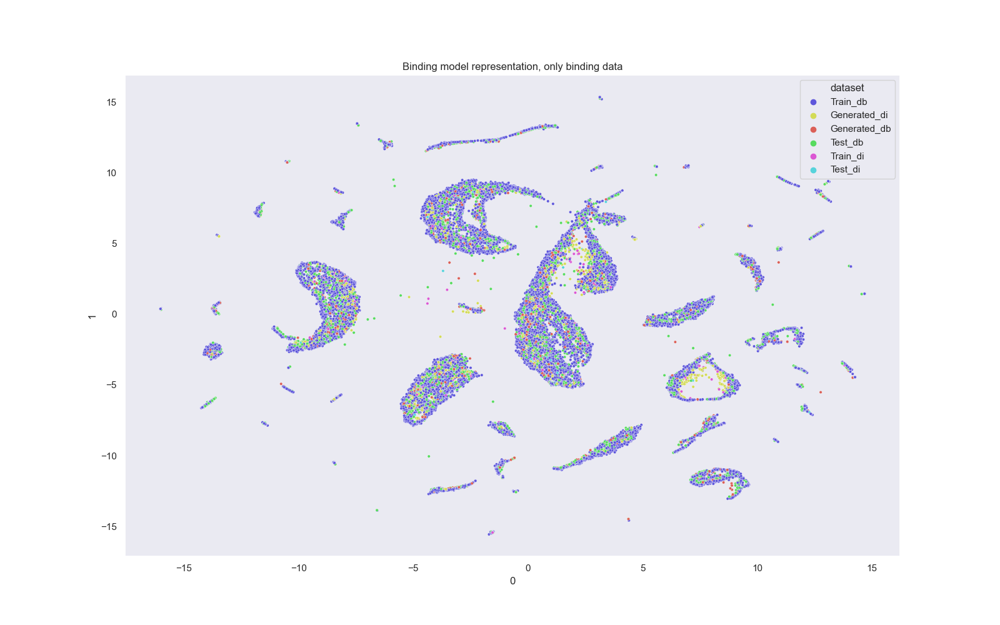

In [88]:
target_df = total_embedding_data['mb']
# target_df = target_df[target_df['dataset'].str.endswith("db")]
fig = make_scatter_plot_sns(target_df, title="Binding model representation, only binding data", colors= colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
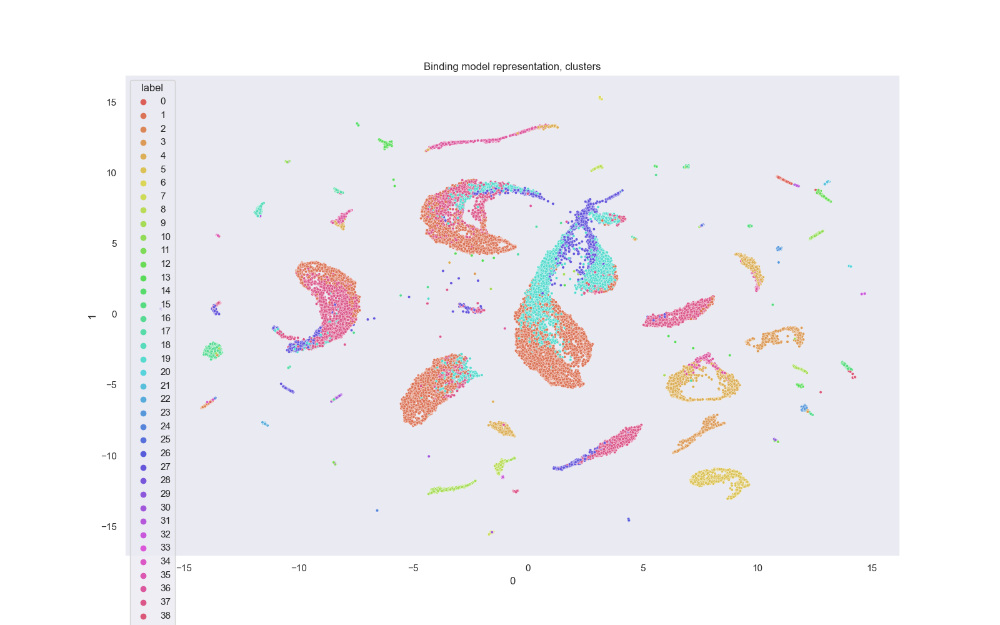

In [89]:
fig = make_scatter_plot_sns(target_df, title='Binding model representation, clusters', hue_column='label')

 label 0
 label 1
 label 2
 label 3
 label 4
 label 5
 label 6
 label 7
 label 8
 label 9
 label 10
 label 11
 label 12
 label 13
 label 14
 label 15
 label 16
 label 17
 label 18
 label 19
 label 20
 label 21
 label 22
 label 23
 label 24
 label 25
 label 26
 label 27
 label 28
 label 29
 label 30
 label 31
 label 32
 label 33
 label 34
 label 35
 label 36
 label 37
 label 38
 label 39


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
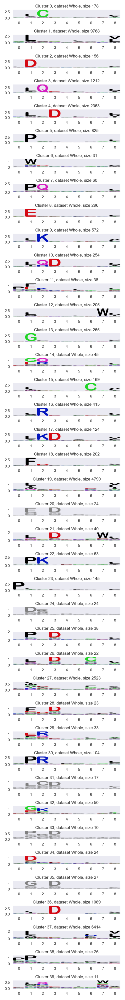

In [90]:
fig = logo_pictures_for_clusters(target_df)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
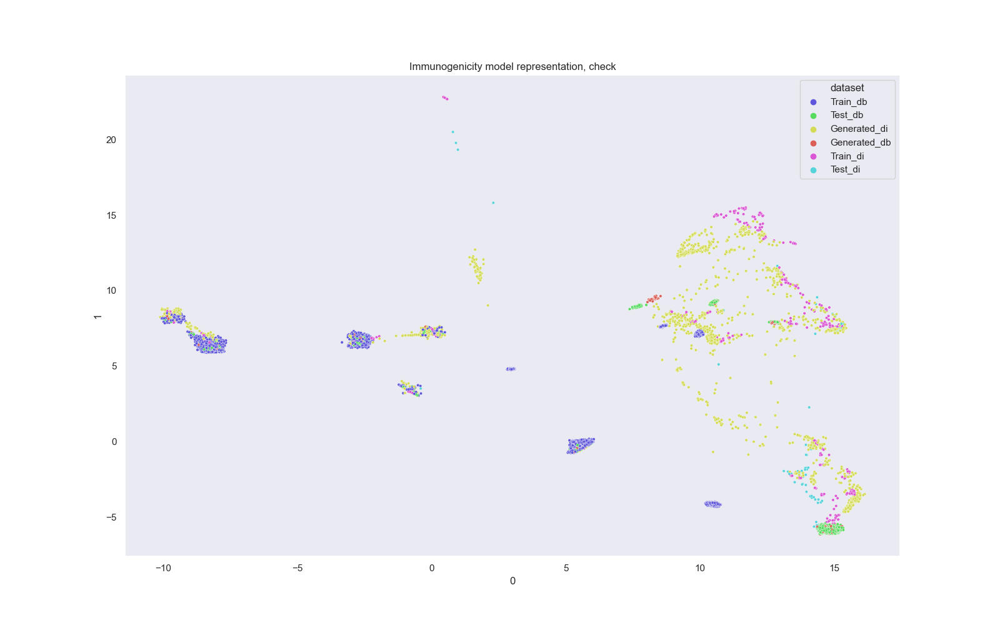

In [85]:
target_df = total_embedding_data['mi']
# target_df = target_df[target_df['dataset'].str.endswith("db")]
fig = make_scatter_plot_sns(target_df, title="Immunogenicity model representation, check", colors= colors)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
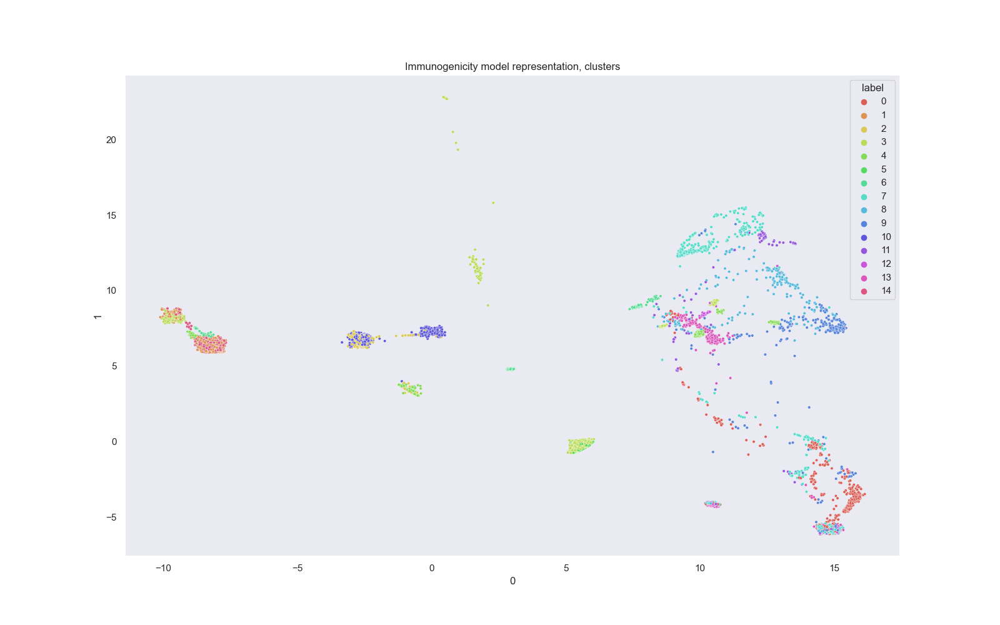

In [86]:
fig = make_scatter_plot_sns(target_df, title='Immunogenicity model representation, clusters', hue_column='label')

C:\Users\denkl\AppData\Local\Temp/ipykernel_11528/1186964750.py:9: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, axes = plt.subplots(ncols=len(unique_datasets), nrows=len(unique_labels), figsize=[5*(len(unique_datasets)), 1*(len(unique_labels))])


 label 0
 label 1
 label 2
 label 3
 label 4
 label 5
 label 6
 label 7
 label 8
 label 9
 label 10
 label 11
 label 12
 label 13
 label 14


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
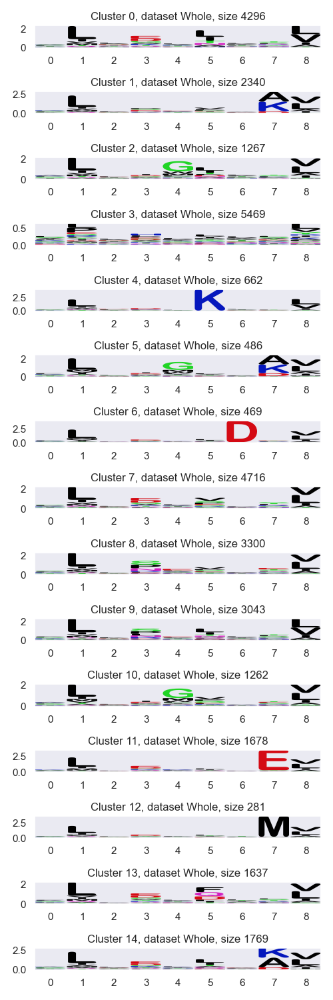

In [87]:
fig = logo_pictures_for_clusters(target_df)